<a href="https://colab.research.google.com/github/leonIceHot/Computer-Vision-Course/blob/main/CH2_%E8%89%B2%E5%BD%A9%E7%A9%BA%E9%96%93.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🖼️ 1. 數位影像底層與屬性 (Digital Image Basics)

## 影像維度、解析度與形狀（Shape: H, W, C）


In [ ]:
import cv2

src = cv2.imread("images.jpg",cv2.IMREAD_GRAYSCALE)
print("列印灰階影像的屬性")
print(f"shape = {src.shape}")
print(f"size  = {src.size}")
print(f"dtype = {src.dtype}")

列印灰階影像的屬性
shape = (371, 538)
size  = 199598
dtype = uint8


## 二值影像 (Binary Image）
是每個像素只能取兩個值的數位影像
- 0 代表黑色
- 1 代表白色

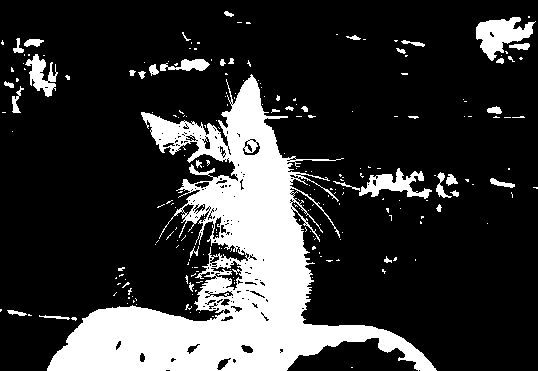

In [ ]:
import cv2
from google.colab.patches import cv2_imshow

img = cv2.imread("images.jpg", cv2.IMREAD_GRAYSCALE)      # 讀成灰階
_, bw = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)   # 大於 127 → 255，其餘 → 0

cv2_imshow(bw)



## 灰階影像 (Grayscale Image）
在最常見的 **8 位元（8-bit）** 灰階影像中：
* 每個像素佔用 1 個位元組（Byte），數值範圍為 **$0 \sim 255$**（共 $2^8 = 256$ 個階層）。
  * **$0$**：代表純黑（完全無光）。
  * **$255$**：代表純白（亮度最大）。
  * **$1 \sim 254$**：代表由暗到亮、不同深淺的灰色階調。

> **補充**：在醫療或天文等高精度領域，亦常用 **12 位元（$0 \sim 4095$）** 或 **16 位元（$0 \sim 65535$）** 來記錄更細微的明暗對比。

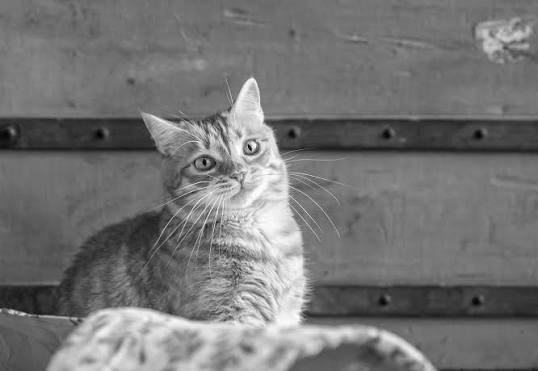

In [ ]:
import cv2
from google.colab.patches import cv2_imshow

src = cv2.imread("images.jpg",cv2.IMREAD_GRAYSCALE)   # 灰階讀取
cv2_imshow(src)

## 彩色影像 (Color Image)

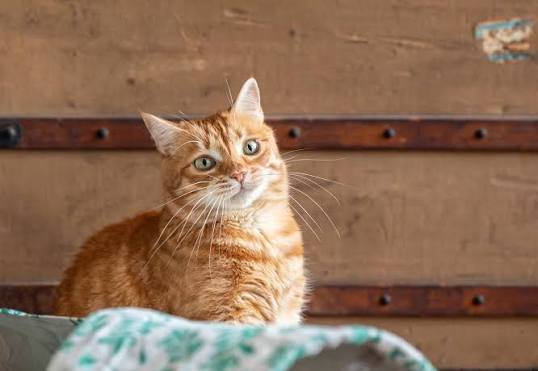

BGR = 72, 98, 134


In [ ]:
import cv2
from google.colab.patches import cv2_imshow

pt_y = 169
pt_x = 118
img = cv2.imread("images.jpg")      # 彩色讀取
cv2_imshow(img)

blue = img[pt_y, pt_x, 0]       # 讀 B 通道值
green = img[pt_y, pt_x, 1]      # 讀 G 通道值
red = img[pt_y, pt_x, 2]       # 讀 R 通道值
print(f"BGR = {blue}, {green}, {red}")

## 資料型態（uint8 vs. float32）與取值範圍正規化

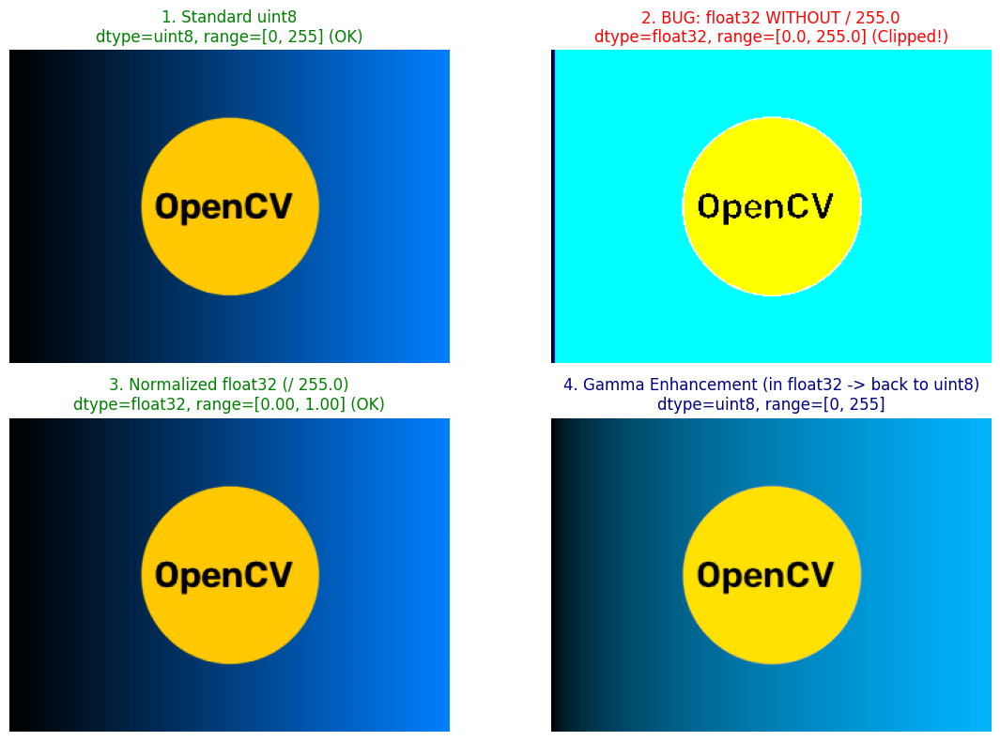

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 建立一張標準 uint8 [0, 255] 測試影像 (含背景漸層與彩色圓形)
H, W = 250, 350
img_uint8 = np.zeros((H, W, 3), dtype=np.uint8)

# 產生水平方向 0~255 的漸層背景
gradient = np.linspace(0, 255, W, dtype=np.uint8)
img_uint8[:, :, 0] = gradient             # Blue 漸層
img_uint8[:, :, 1] = gradient // 2        # Green 漸層
cv2.circle(img_uint8, (175, 125), 70, (0, 200, 255), -1, cv2.LINE_AA)
cv2.putText(img_uint8, "OpenCV", (115, 135), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 0, 0), 3, cv2.LINE_AA)

# ==========================================================
# 實驗組 A：標準 uint8 [0, 255] -> 正常顯示
# ==========================================================
rgb_uint8 = cv2.cvtColor(img_uint8, cv2.COLOR_BGR2RGB)

# ==========================================================
# 實驗組 B：【經典錯誤！】轉成 float32 但沒除以 255 (範圍仍是 0.0~255.0)
# Matplotlib 會把所有 > 1.0 的像素全部當成爆表純白！
# ==========================================================
rgb_float_wrong = rgb_uint8.astype(np.float32)

# ==========================================================
# 實驗組 C：【正確正規化】轉成 float32 並除以 255.0 (範圍 0.0~1.0)
# ==========================================================
rgb_float_norm = rgb_uint8.astype(np.float32) / 255.0

# ==========================================================
# 實驗組 D：在 float32 [0.0, 1.0] 下做 Gamma 調亮增強，再安全轉回 uint8
# ==========================================================
gamma = 0.5  # Gamma < 1 會提亮暗部細節 (必須在 0.0~1.0 浮點數下做次方運算！)
rgb_gamma_float = np.power(rgb_float_norm, gamma)
rgb_gamma_uint8 = np.clip(rgb_gamma_float * 255.0, 0, 255).astype(np.uint8)

# ==========================================================
# 使用 Matplotlib 2x2 並列顯示對照
# ==========================================================
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# 圖 1: 標準 uint8
axes[0, 0].imshow(rgb_uint8)
axes[0, 0].set_title(f"1. Standard uint8\ndtype={rgb_uint8.dtype}, range=[{rgb_uint8.min()}, {rgb_uint8.max()}] (OK)", color="green")

# 圖 2: 錯誤的 float32 (未正規化)
axes[0, 1].imshow(rgb_float_wrong)
axes[0, 1].set_title(f"2. BUG: float32 WITHOUT / 255.0\ndtype={rgb_float_wrong.dtype}, range=[{rgb_float_wrong.min():.1f}, {rgb_float_wrong.max():.1f}] (Clipped!)", color="red")

# 圖 3: 正確正規化的 float32
axes[1, 0].imshow(rgb_float_norm)
axes[1, 0].set_title(f"3. Normalized float32 (/ 255.0)\ndtype={rgb_float_norm.dtype}, range=[{rgb_float_norm.min():.2f}, {rgb_float_norm.max():.2f}] (OK)", color="green")

# 圖 4: 浮點數非線性運算 (Gamma=0.5) 後轉回 uint8
axes[1, 1].imshow(rgb_gamma_uint8)
axes[1, 1].set_title(f"4. Gamma Enhancement (in float32 -> back to uint8)\ndtype={rgb_gamma_uint8.dtype}, range=[{rgb_gamma_uint8.min()}, {rgb_gamma_uint8.max()}]", color="navy")

for ax in axes.flatten():
    ax.axis("off")

plt.tight_layout()
plt.show()


## 影像取樣（Sampling）與量化（Quantization）深度解析


將連續的真實世界畫面轉換為電腦可儲存的「數位影像」，必須經過兩個核心數位化步驟：**取樣（Sampling）** 與 **量化（Quantization）**。

---

## 1. 核心觀念介紹

1. **取樣（Sampling）—— 座標空間的數位化**
   * **定義**：決定在水平（`x`）與垂直（`y`）方向上要切割出多少個網格點（Pixels）。
   * **對應屬性**：決定影像的 **空間解析度（Spatial Resolution，如 `256 * 256`）**。
   * **不足時的失真現象**：取樣率過低時，影像細節遺失，邊緣出現明顯的鋸齒與方塊感，稱為 **棋盤格效應（Checkerboard Effect / 馬賽克現象）**。

2. **量化（Quantization）—— 振幅強度的數位化**
   * **定義**：將每個取樣點（像素）的連續亮度/色彩強度，對應到有限的離散數值階數（如 `0 ~ 255`）。
   * **對應屬性**：決定影像的 **灰階/色彩解析度（Gray-level Resolution / Bit Depth，如 8-bit 代表 `2^8 = 256` 階）**。
   * **不足時的失真現象**：量化階數過低時，原本平滑的明暗漸層會斷裂成一圈一圈的色塊，稱為 **假輪廓（False Contouring / 色帶現象）**。

---

## 2. 取樣 vs 量化 對照表

| 比較項目 | 取樣（Sampling） | 量化（Quantization） |
| :--- | :--- | :--- |
| **轉換對象** | 空間座標（`$x, y$` 位置） | 像素強度（振幅 / 亮度 / 顏色值） |
| **決定指標** | 空間解析度（`$W \times H$` 像素數量） | 位元深度（Bit Depth，如 8-bit = `$256$` 階） |
| **數值越高的影響** | 畫面越清晰細膩、檔案越大 | 色彩過渡越平滑自然、檔案越大 |
| **數值過低的失真** | **馬賽克 / 棋盤格效應（Pixelation）** | **假輪廓 / 色帶現象（False Contouring）** |

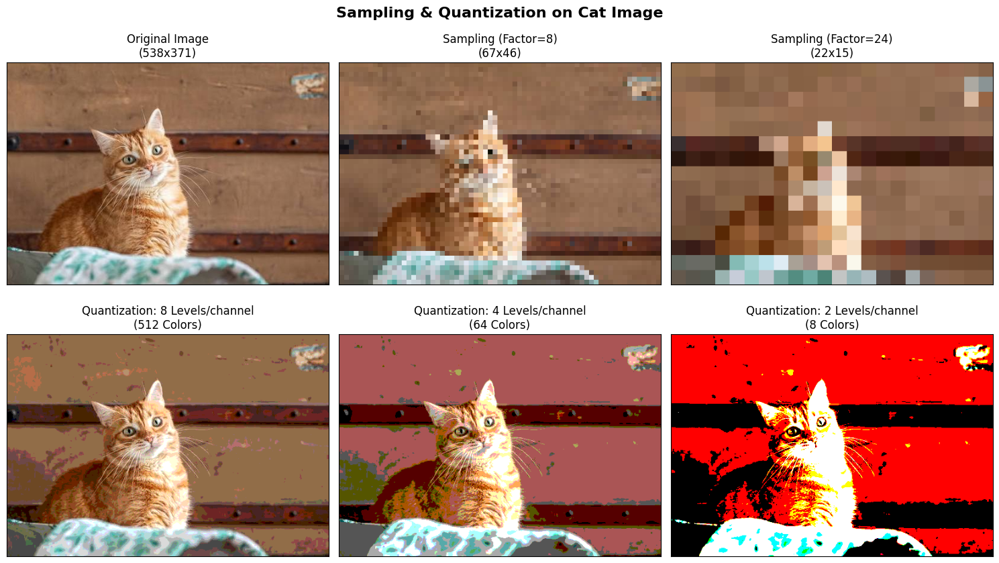

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# 如果在 Google Colab 執行，打開以下兩行可直接上傳圖片：
# from google.colab import files
# uploaded = files.upload() # 選擇你下載的這張貓咪照片


# --- 1. 取樣函式 (降低空間解析度) ---
def down_sample(img, factor):
    """factor: 降取樣倍數 (例如 factor=16 代表長寬各縮小為 1/16)"""
    h, w = img.shape[:2]
    # 先縮小 (丟棄大部分像素取樣點)
    small = cv2.resize(
        img, (w // factor, h // factor), interpolation=cv2.INTER_NEAREST
    )
    # 再放大回原圖大小 (用最近鄰插值，呈現方格馬賽克顆粒)
    pixelated = cv2.resize(small, (w, h), interpolation=cv2.INTER_NEAREST)
    return pixelated


# --- 2. 量化函式 (降低色彩/灰階階數) ---
def quantize(img, levels):
    """levels: 每個色彩通道的階數 (例如 levels=4，R、G、B 各只保留 4 個亮度等級)"""
    step = 256.0 / levels
    quantized = np.floor(img / step) * (255.0 / (levels - 1))
    return quantized.astype(np.uint8)


# --- 3. 讀取並處理圖片 ---
# 讀取貓咪圖片 (若檔名不同請自行修改)
img_bgr = cv2.imread("images.jpg")

# 檢查是否成功讀取，若讀不到可拋出提示
if img_bgr is None:
    raise FileNotFoundError("找不到 cat.jpg，請確認圖片已放在同目錄中！")

# OpenCV 預設是 BGR，轉為 RGB 以便 Matplotlib 正確顯示橘色
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

# A. 進行不同程度的「取樣」 (長寬縮小倍數)
sample_1 = img_rgb  # 原圖
sample_2 = down_sample(img_rgb, factor=8)  # 輕微馬賽克
sample_3 = down_sample(img_rgb, factor=24)  # 強烈像素風格 (像素藝術風)

# B. 進行不同程度的「量化」 (色階數量)
quant_1 = quantize(img_rgb, levels=8)  # 每個通道 8 階 (8x8x8 = 512 種顏色)
quant_2 = quantize(img_rgb, levels=4)  # 每個通道 4 階 (4x4x4 = 64 種顏色)
quant_3 = quantize(img_rgb, levels=2)  # 每個通道 2 階 (2x2x2 = 8 種極限基本色)

# --- 4. 繪製 2x3 比較圖 ---
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

# 第一排：取樣 (Sampling) - 空間解析度變化
axes[0, 0].imshow(sample_1)
axes[0, 0].set_title(
    f"Original Image\n({img_rgb.shape[1]}x{img_rgb.shape[0]})", fontsize=12
)

axes[0, 1].imshow(sample_2)
axes[0, 1].set_title(
    f"Sampling (Factor=8)\n({img_rgb.shape[1]//8}x{img_rgb.shape[0]//8})",
    fontsize=12,
)

axes[0, 2].imshow(sample_3)
axes[0, 2].set_title(
    f"Sampling (Factor=24)\n({img_rgb.shape[1]//24}x{img_rgb.shape[0]//24})",
    fontsize=12,
)

# 第二排：量化 (Quantization) - 色彩階數變化
axes[1, 0].imshow(quant_1)
axes[1, 0].set_title("Quantization: 8 Levels/channel\n(512 Colors)", fontsize=12)

axes[1, 1].imshow(quant_2)
axes[1, 1].set_title("Quantization: 4 Levels/channel\n(64 Colors)", fontsize=12)

axes[1, 2].imshow(quant_3)
axes[1, 2].set_title("Quantization: 2 Levels/channel\n(8 Colors)", fontsize=12)

# 隱藏座標軸刻度並保留外框
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle(
    "Sampling & Quantization on Cat Image", fontsize=16, fontweight="bold"
)
plt.tight_layout()
plt.show()


# 🔀 2. 通道操作與效能 (Channel Operations)


## 感興趣區域 (Region Of Interest)


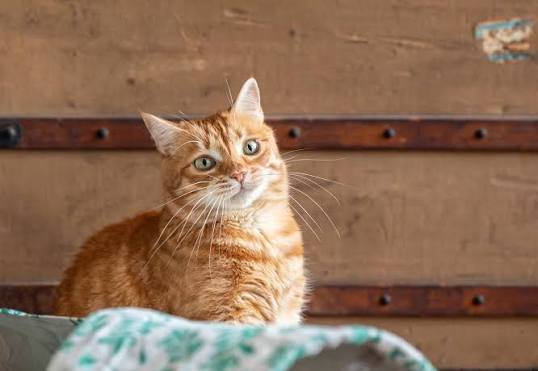

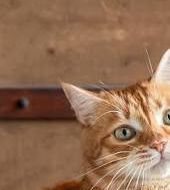

In [ ]:
import cv2
from google.colab.patches import cv2_imshow

image = cv2.imread("images.jpg") # 彩色讀取
cv2_imshow(img)  # 顯示影像
face = img[30:220,80:250]    # ROI
cv2_imshow(face)     # 顯示影像

## 通道拆分 (Split)

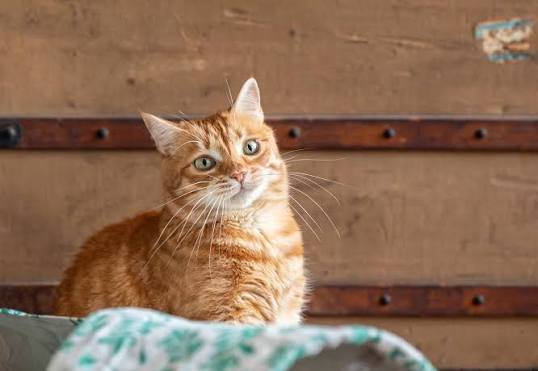

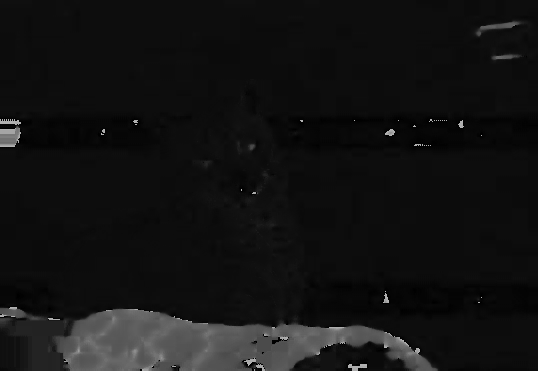

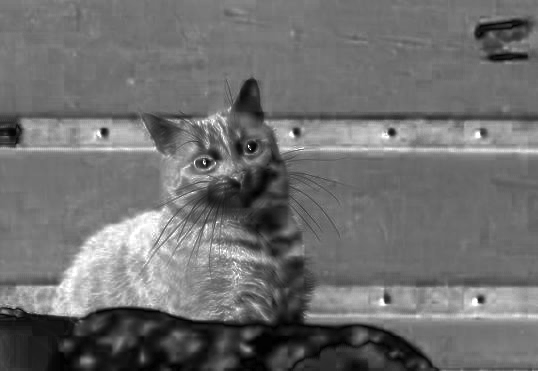

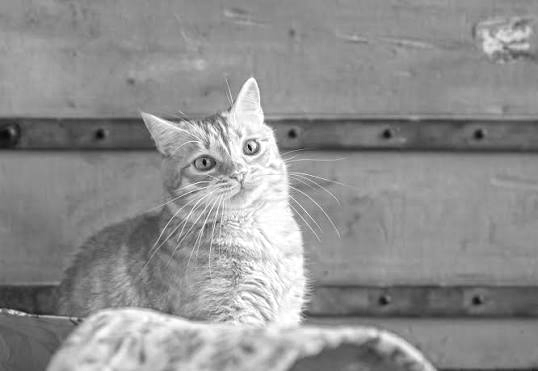

In [ ]:
import cv2
from google.colab.patches import cv2_imshow

img = cv2.imread("images.jpg")
cv2_imshow(img)

hsv_image = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
hue, saturation, value = cv2.split(hsv_image)
cv2_imshow(hue)
cv2_imshow(saturation)
cv2_imshow(value)

## 通道合併 (Merge)

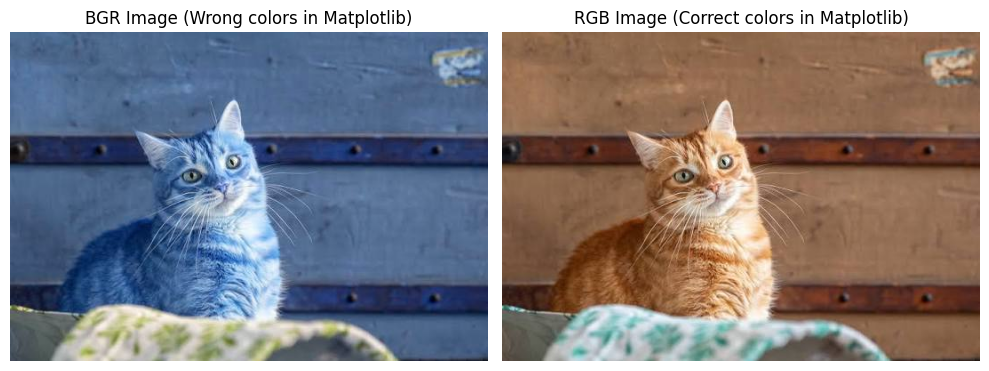

In [ ]:
import cv2
import matplotlib.pyplot as plt

# 1. 讀取圖片 (OpenCV 預設讀取為 B, G, R 順序)
image = cv2.imread("images.jpg")

# 2. 正確拆解通道：順序應為 Blue, Green, Red
blue, green, red = cv2.split(image)

# 3. 依據不同順序重新合併
bgr_image = cv2.merge([blue, green, red])  # 維持 B, G, R 順序
rgb_image = cv2.merge([red, green, blue])  # 轉為 R, G, B 順序

# 4. 使用 Matplotlib 並排顯示圖片
plt.figure(figsize=(10, 5))

# 左圖：顯示 BGR 圖片 (在 Matplotlib 中紅藍會顛倒，顏色異常)
plt.subplot(1, 2, 1)
plt.imshow(bgr_image)
plt.title("BGR Image (Wrong colors in Matplotlib)")
plt.axis("off")  # 隱藏座標軸

# 右圖：顯示 RGB 圖片 (在 Matplotlib 中顏色正常)
plt.subplot(1, 2, 2)
plt.imshow(rgb_image)
plt.title("RGB Image (Correct colors in Matplotlib)")
plt.axis("off")  # 隱藏座標軸

plt.tight_layout()
plt.show()


## 高效替代方案：NumPy 切片索引與單通道著色視覺化


## 包含透明度的四通道：BGRA / RGBA 格式

### BGRA 色彩格式介紹

**BGRA** 代表 **Blue（藍）、Green（綠）、Red（紅）、Alpha（透明度）**。它是一種常見於電腦圖形學、圖像處理以及影片渲染中的數位色彩格式與像素記憶體排列方式。

---

## 1. 色彩通道組成

在最常見的 32 位元（每通道 8 位元，8-bit per channel）圖像中：

| 通道 | 名稱 | 數值範圍 | 說明 |
| :---: | :--- | :---: | :--- |
| **B** | Blue（藍色） | $$0 \sim 255$$ | 控制藍色光強度 |
| **G** | Green（綠色） | $$0 \sim 255$$ | 控制綠色光強度 |
| **R** | Red（紅色） | $$0 \sim 255$$ | 控制紅色光強度 |
| **A** | Alpha（透明度） | $$0 \sim 255$$ | $$0$$ 為完全透明，$$255$$ 為完全不透明 |

---

## 2. 為什麼是 BGRA 而不是 RGBA？

雖然在網頁前端（CSS/Canvas）和平面設計軟體中最常見的是 **RGBA**，但在底層圖形系統中 **BGRA** 極為普遍，主要原因與硬體架構有關：

* **小端序架構（Little-Endian）：**  
  現代主流的 x86/x64 與 ARM 處理器皆採用小端序（低位元組在記憶體前段）。當一個 32 位元的色彩整數以 `0xAARRGGBB` 形式載入暫存器時，其在實體記憶體中的連續位元組順序剛好是：
  $$\text{Byte 0: B} \quad\longrightarrow\quad \text{Byte 1: G} \quad\longrightarrow\quad \text{Byte 2: R} \quad\longrightarrow\quad \text{Byte 3: A}$$
* **硬體傳輸效率：**  
  為了讓記憶體中的像素資料能以零成本（Zero-Copy）的方式直接送進顯示卡（GPU）渲染，許多顯示驅動與圖形 API 預設直接採用 BGRA 作為原生排列。

---

## 3. 常見應用場景

* **OpenCV：**  
  OpenCV 讀取與處理圖片時，歷史上預設使用 **BGR**（若含透明度則為 **BGRA**），而非 RGB。
* **Windows 圖形架構（GDI / Direct2D / DirectX）：**  
  Windows 早期的點陣圖格式（如 `.bmp`）即為 BGR 排列；DirectX 的交換鏈（Swap Chain）最常用的格式之一便是 `DXGI_FORMAT_B8G8R8A8_UNORM`。
* **Apple 生態系（Metal / Core Graphics / AVFoundation）：**  
  在 iOS / macOS 開發中，相機即時串流影像與 GPU 紋理常用 `kCVPixelFormatType_32BGRA`。
* **跨平台 GPU API（Vulkan / WebGPU）：**  
  在多數桌面端顯示器介面上，Surface 的原生首選交換鏈格式往往也是 BGRA。

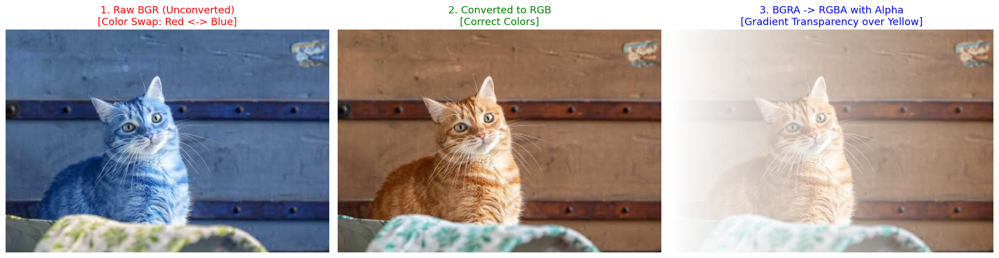

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# 1. 讀取標準 images.jpg（OpenCV 預設讀入為 BGR 格式，維度形狀為 (H, W, 3)）
img_bgr = cv2.imread("images.jpg")

if img_bgr is None:
    raise FileNotFoundError("請確認 'images.jpg' 檔案是否存在於目前的目錄中！")

h, w, _ = img_bgr.shape

# 2. 將 BGR 正確轉換為 RGB（供 Matplotlib 正確還原色彩）
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

# 3. 轉為 BGRA 格式，並手動生成水平漸層作為 Alpha 透明通道
img_bgra = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2BGRA)

# 建立漸層遮罩：左邊 0（完全透明） -> 右邊 255（完全不透明）
alpha_mask = np.linspace(0, 255, w, dtype=np.uint8)
alpha_mask = np.tile(alpha_mask, (h, 1))

# 將計算好的遮罩填入第 4 通道（Alpha 通道）
img_bgra[:, :, 3] = alpha_mask

# 4. 將帶有透明度的 BGRA 轉為 RGBA，供 Matplotlib 進行透明度渲染
img_rgba = cv2.cvtColor(img_bgra, cv2.COLOR_BGRA2RGBA)

# -------------------------------------------------------------
# 5. 使用 Matplotlib 畫布對比三者差異
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# (1) 錯誤用法：直接將 BGR 傳入 Matplotlib（紅藍通道顛倒）
axes[0].imshow(img_bgr)
axes[0].set_title("1. Raw BGR (Unconverted)\n[Color Swap: Red <-> Blue]", fontsize=13, color="red")
axes[0].axis("off")

# (2) 正確用法：轉換為標準 RGB
axes[1].imshow(img_rgb)
axes[1].set_title("2. Converted to RGB\n[Correct Colors]", fontsize=13, color="green")
axes[1].axis("off")

# (3) 帶透明通道：底色設為黃色以清楚透出漸層穿透效果
axes[2].set_facecolor("yellow")
axes[2].imshow(img_rgba)
axes[2].set_title("3. BGRA -> RGBA with Alpha\n[Gradient Transparency over Yellow]", fontsize=13, color="blue")
axes[2].axis("off")

plt.tight_layout()
plt.show()


# 🎨 3. 經典色彩空間詳解與轉換 (Color Spaces)

色彩空間轉換與應用

本模組涵蓋 OpenCV 中的各種色彩空間，從基礎概念到實際應用。

## 學習目標
- 理解不同色彩空間的特性與用途
- 掌握 BGR、RGB、Gray、HSV、HLS、LAB、YCrCb之間的轉換
- 學習色彩空間在實際應用中的選擇策略


## 色彩空間基礎概念

### 什麼是色彩空間？
色彩空間（Color Space）是一種用數學方式描述顏色的模型。在電腦視覺與影像處理中，不同的色彩空間有不同的特徵表示方法，選擇合適的色彩空間能大幅簡化演算法的複雜度。

### 常見色彩空間

1. **BGR/RGB** - 加法混色模型
4. **Grayscale** - 灰階   
2. **HSV** - 色相、飽和度、明度
3. **LAB** - 感知均勻色彩空間
   


## RGB / BGR 色彩空間
**RGB 色彩空間**是最基礎、最常見的色彩表示法，屬於**加法混色模型（Additive Color Model）**——數值越高代表光線疊加越多，越接近白色；反之全為 0 則為純黑。

## 1. 三大核心要素與數值範圍

| 屬性 | 英文名稱 | 定義說明 | OpenCV 範圍 (8-bit) |
| :--- | :--- | :--- | :--- |
| **紅色** | **R** (Red) | 紅色光通道強度 | 0 ~ 255 |
| **綠色** | **G** (Green) | 綠色光通道強度 | 0 ~ 255 |
| **藍色** | **B** (Blue) | 藍色光通道強度 | 0 ~ 255 |

> ⚠️ **注意通道順序**：大多數軟體與函式庫（如 Matplotlib、PIL）預設使用 **RGB** 順序；但 **OpenCV 預設使用 BGR 順序**（藍、綠、紅）。若未進行轉換直接混用，畫面顏色會失真（紅藍顛倒）。

## 2. 為什麼 OpenCV 預設使用 BGR 順序？
* **歷史與硬體相容性**：在 OpenCV 開發初期，許多主流的相機製造商、影像擷取卡與軟體（如 Windows 的 `BITMAP` 格式）普遍採用 **BGR** 的記憶體排列順序。OpenCV 為了保持與底層硬體及舊有系統的相容性，便將 BGR 設為預設標準並延續至今。

## 3. RGB / BGR 的特性與限制
1. **符合硬體結構**：直接對應螢幕顯示器（發光二極體）與相機感光元件（Bayer Filter）的物理運作方式。
2. **色彩與亮度耦合（限制）**：R、G、B 三個通道同時包含了「顏色」與「亮度」資訊。當環境光線改變時，三個通道的數值會同時變動，因此在進行特定顏色提取時較不如 HSV 直覺。

## 4. 常見應用場景
- **影像顯示 (Image Display)**：螢幕輸出、視窗顯示與各類圖形介面呈現。
- **基本影像處理 (Basic Image Processing)**：影像讀取/儲存、幾何變換（縮放、旋轉、裁切）、繪製幾何圖形或文字。


彩色影像

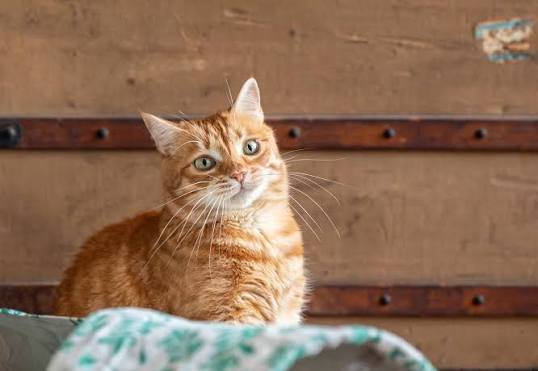

In [ ]:
import cv2
from google.colab.patches import cv2_imshow

img = cv2.imread("images.jpg")
cv2_imshow(img)


全黑的影像

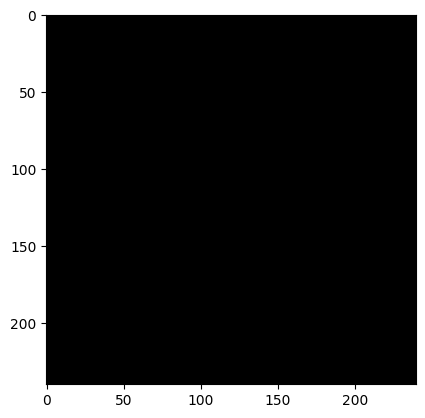

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 建立一張 480x640 全黑影像 (height, width, channels)
height, width = 240, 240
black_image = np.zeros((height, width, 3), dtype=np.uint8)

plt.imshow(black_image)
plt.show()


全白的影像

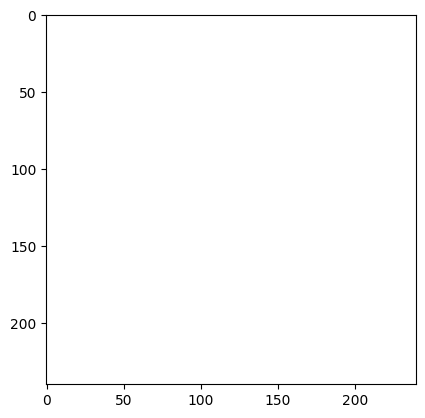

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

height, width = 240, 240
white_image = np.ones((height, width, 3), dtype=np.uint8) * 255

plt.imshow(white_image)
plt.show()


## Grayscale 色彩空間
將彩色影像（RGB / BGR）轉換為單通道灰階影像的常見方法與實作整理。

1. 加權平均法（推薦） - **cv2.cvtColor()**
  * 人眼對不同顏色的敏感度不同（**綠 > 紅 > 藍**）。依照 ITU-R BT.601 標準賦予不同權重，最符合人類視覺感知。
  * **公式**：
    $\text{Gray} = 0.299 \times R + 0.587 \times G + 0.114 \times B$
    * **優點**：保留的明暗對比最自然，細節最豐富。

2. **平均法** - 簡單平均
  * 不考慮人眼感光差異，直接將三個通道數值相加除以 $3$。
  * **公式**：
    $\text{Gray} = \frac{R + G + B}{3}$
    * **優點**：概念簡單直觀。
    * **缺點**：對比度較差（如純藍與純綠會變成相同亮度）。
    * **注意**：直接將 `uint8` 相加會超過 $255$ 造成溢位（Overflow），需先轉型或使用 `np.mean`。

3. **單通道** - 直接取一個通道
  * 直接抽取 $B$、$G$、$R$ 其中一個通道作為灰階值。
  * **公式**：
    $\text{Gray} = R \quad \text{或} \quad \text{Gray} = G \quad \text{或} \quad \text{Gray} = B$
  * **優點**：零計算、運算速度極快。
  * **應用場景**：
    * **取 $G$ 通道**：因綠色佔人眼感光近 $60\%$，效能受限時可作為灰階的快速近似。
    * **特定顏色提取**：如凸顯紅色印章或雷射光點時，可直接取 $R$ 通道。

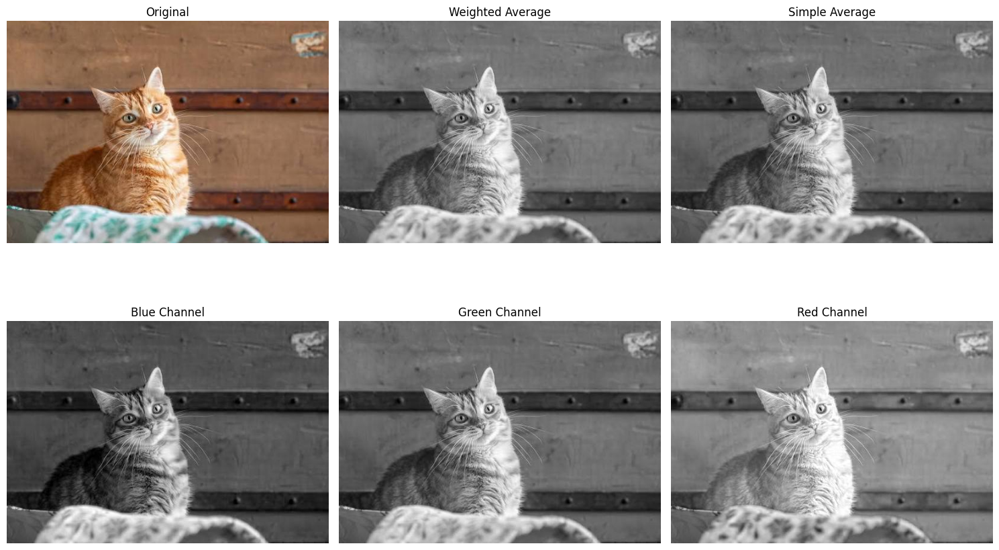

Grayscale conversion comparison:
Weighted Average   mean=116.61  std= 41.43
Simple Average     mean=112.34  std= 41.28
Blue Channel       mean= 86.93  std= 46.48
Green Channel      mean=109.67  std= 44.07
Red Channel        mean=141.51  std= 38.10


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ---------- 讀圖 ----------
img = cv2.imread("images.jpg")          # BGR 順序
if img is None:
    raise FileNotFoundError("讀不到 images.jpg")

b, g, r = cv2.split(img)

# ---------- 各種灰階轉換 ----------
gray_weighted = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)   # 加權平均
gray_average  = img.mean(axis=2).astype(np.uint8)       # 簡單平均

results = [
    ("Original",cv2.cvtColor(img, cv2.COLOR_BGR2RGB)),
    ("Weighted Average",gray_weighted),
    ("Simple Average",gray_average),
    ("Blue Channel",b),
    ("Green Channel",g),
    ("Red Channel",r),
]

# ---------- 顯示 ----------
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for ax, (title, im) in zip(axes.ravel(), results):
    if im.ndim == 2:
        ax.imshow(im, cmap="gray", vmin=0, vmax=255)   # 固定範圍，避免自動拉伸造成誤判
    else:
        ax.imshow(im)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# ---------- 統計比較 ----------
print("Grayscale conversion comparison:")
for title, im in results[1:]:
    print(f"{title:<18} mean={im.mean():6.2f}  std={im.std():6.2f}")


## HSV 色彩空間
相較於傳統的 RGB 色彩空間，**HSV 色彩空間**將顏色的「色彩資訊」與「明暗程度」分開，更接近人類直覺感知顏色的方式。

## 1. 三大核心要素與數值範圍

| 屬性 | 英文名稱 | 定義說明 | OpenCV 範圍 (8-bit) | 標準理論範圍 |
| :--- | :--- | :--- | :--- | :--- |
| **色相** | **H** (Hue) | 顏色的基本種類（如：紅、綠、藍等） | 0 ~ 180° | 0° ~ 360° |
| **飽和度** | **S** (Saturation) | 顏色的純度與鮮豔程度（越低越接近灰色） | 0 ~ 255 | 0% ~ 100% |
| **明度** | **V** (Value) | 顏色的明亮程度（0 為純黑，越高越亮） | 0 ~ 255 | 0% ~ 100% |

> 💡 **補充說明**：在 OpenCV 中，為了將色相（原本為 0° ~ 360°）存入 1 個 Byte（最大表示 0 ~ 255）中，會將角度除以 2，因此範圍變成 **0 ~ 180**。

## 2. HSV 的核心優勢
1. **色彩檢測更容易**：顏色種類集中在單一通道，通常只需指定 **色相 (H)** 的範圍，即可輕鬆過濾出特定顏色。
2. **對光照變化更具魯棒性 (Robustness)**：環境光線的明暗變化主要影響 **明度 (V)**，不太會改變色相 (H)，使演算法在陰影或強光下依然穩定。
3. **色彩與亮度解耦**：將「顏色 (H、S)」與「亮度 (V)」分開，方便進行獨立的影像分析與調整。

## 3. 常見應用場景
- **色彩檢測 (Color Detection)**：如辨識交通號誌、特定顏色的瑕疵檢測。
- **物體追蹤 (Object Tracking)**：鎖定特定顏色的移動目標（如追蹤網球、顏色標記物）。
- **色彩分割 (Color Segmentation)**：將特定顏色的前景與背景快速分離（如綠幕去背、車道線提取）。


shape = (371, 538, 3), dtype = uint8
H 範圍: 0 ~ 179
S 範圍: 0 ~ 255
V 範圍: 2 ~ 255


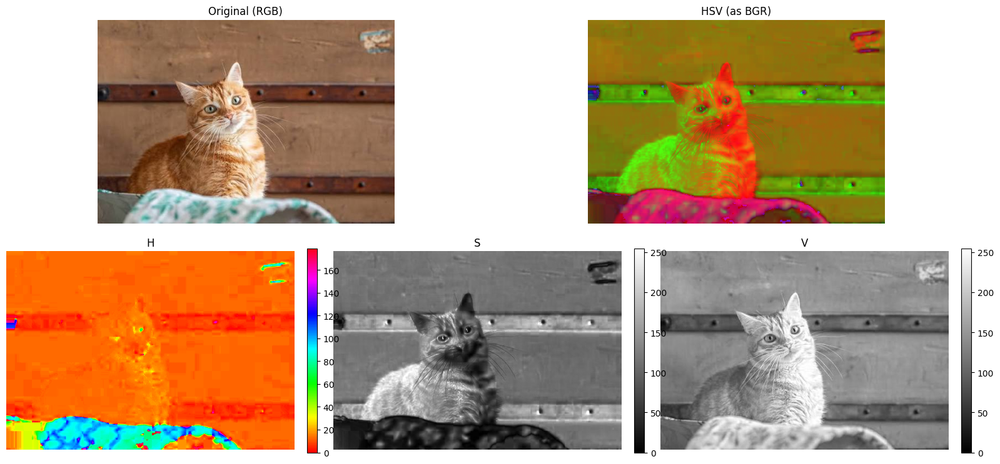

In [ ]:
# ============================================================
# BGR -> HSV 視覺化（2 列：上排 Original/HSV，下排 H/S/V）
# ============================================================
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ---------- 1. 讀圖 ----------
path = "images.jpg"
img = cv2.imread(path)          # imread 是 BGR 順序
if img is None:
    raise FileNotFoundError(f"讀不到 {path}，請確認檔名與路徑")

print(f"shape = {img.shape}, dtype = {img.dtype}")

# ---------- 2. 色彩空間轉換 ----------
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)   # 給 matplotlib 用
img_hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)   # 給 HSV 分析用

# ---------- 3. 分離通道 ----------
h, s, v = cv2.split(img_hsv)

print(f"H 範圍: {h.min()} ~ {h.max()}")   # OpenCV Hue 是 0~179
print(f"S 範圍: {s.min()} ~ {s.max()}")
print(f"V 範圍: {v.min()} ~ {v.max()}")

# ---------- 4. 2 列排版 ----------
fig = plt.figure(figsize=(20, 9))
gs = fig.add_gridspec(2, 6, hspace=0.12, wspace=0.08)

ax_orig = fig.add_subplot(gs[0, 0:3])   # 上排左
ax_hsv  = fig.add_subplot(gs[0, 3:6])   # 上排右
ax_h    = fig.add_subplot(gs[1, 0:2])   # 下排 H
ax_s    = fig.add_subplot(gs[1, 2:4])   # 下排 S
ax_v    = fig.add_subplot(gs[1, 4:6])   # 下排 V

# --- 上排：Original (RGB) ---
ax_orig.imshow(img_rgb)
ax_orig.set_title("Original (RGB)")

# --- 上排：HSV 當成 BGR 顯示的失真版 ---
# cv2_imshow(img_hsv) 會把 (H,S,V) 當 (B,G,R)；
# matplotlib 要 RGB，所以再反轉一次通道
ax_hsv.imshow(img_hsv[:, :, ::-1])
ax_hsv.set_title("HSV (as BGR)")

# --- 下排：H / S / V 灰階 ---
channels = [
    (ax_h, h, "H", "hsv",  179),   # Hue 用 hsv 色盤，0~179
    (ax_s, s, "S", "gray", 255),
    (ax_v, v, "V", "gray", 255),
]

for ax, ch, name, cmap, vmax in channels:
    im = ax.imshow(ch, cmap=cmap, vmin=0, vmax=vmax)
    ax.set_title(name)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)   # 不需要可刪

for ax in (ax_orig, ax_hsv, ax_h, ax_s, ax_v):
    ax.axis("off")

plt.show()


## HLS 色彩空間

**HLS**（在許多繪圖軟體、網頁 CSS 與設計領域常稱作 **HSL**）是一種將 RGB 三原色重新組織、更符合**人類主觀視覺直覺**的圓柱／雙圓錐座標色彩空間。

它的核心價值是：**將「顏色種類」與「光影明暗」徹底分離（解耦）**，使電腦視覺演算法在面對複雜光照、陰影干擾時具備高度穩定性。

---

## 一、HLS 三個通道的詳細定義

HLS 由三個維度組成，分別代表顏色的本質、能量強度與純淨程度：

* **H (色相)**：光譜的核心本質 ——「是什麼顏色？」
* **L (亮度)**：光線的能量強度 ——「有多亮？白色與黑色比例？」
* **S (飽和度)**：色彩的純淨程度 ——「顏色有多濃？有沒有摻雜灰色？」

---

### 1. H（Hue，色相 / 色調）——「是什麼顏色？」

#### (1) 物理含義與光譜波長
* **定義**：色相反映的是人眼所感知到的單色光**主波長（Dominant Wavelength）**。
* **分佈形式**：色相並非線性分佈，而是一個首尾相接的 **360° 色相環（Color Wheel）**。
* **標準角度對照（每隔 60° 旋轉一種主要原色與二次色）**：
  * **0°（或 360°）**：**純紅色（Red）**（波長最長，約 700 nm）
  * **60°**：**黃色（Yellow）**（紅 ＋ 綠）
  * **120°**：**純綠色（Green）**（波長約 530 nm）
  * **180°**：**青色（Cyan）**（綠 ＋ 藍）
  * **240°**：**純藍色（Blue）**（波長最短，約 470 nm）
  * **300°**：**洋紅色 / 品紅（Magenta）**（藍 ＋ 紅）

#### (2) 數學轉換邏輯（RGB 轉 HLS）
假設 R, G, B 均正規化至 0.0 到 1.0 之間：
* 令 **Max** = 最大值 max(R, G, B)
* 令 **Min** = 最小值 min(R, G, B)
* 令差值 **Delta** = Max - Min

計算邏輯如下：
* 若 **Delta = 0**（即 R = G = B，畫面為無彩色的黑白灰）：H 未定義（程式中通常預設為 0）。
* 若 **Max = R**：H = 60° × ((G - B) / Delta mod 6)
* 若 **Max = G**：H = 60° × ((B - R) / Delta + 2)
* 若 **Max = B**：H = 60° × ((R - G) / Delta + 4)
*(若算出的 H 為負數，則加上 360° 使其落在 0° 到 360° 範圍內)*

#### (3) OpenCV 工程實務注意事項
1. **數值壓縮為 0 到 179**：
   * 標準 8-bit（uint8）的最大值為 255，裝不下 360°。
   * 因此 OpenCV 將角度直接除以 2，範圍壓縮為 **0 到 179**（例如：純紅為 0，純綠 120° 變成 60，純藍 240° 變成 120）。
2. **紅色跨界問題（Red Wraparound）**：
   * 紅色剛好橫跨 0° 兩側（例如 350° 到 10°）。
   * 在 OpenCV 進行紅色物體過濾時，不能單用一個區間，需分兩段取聯集（OR）：
     * 低區間：H 介於 0 到 10
     * 高區間：H 介於 170 到 179

---

### 2. L（Lightness，亮度 / 明度）——「光線有多亮 / 白色黑色比例？」

#### (1) 核心概念與視覺感知
* **定義**：用來衡量該顏色表面反射或發射的**總光通量強度（Photometric Intensity）**。
* **量化尺度**：理論上為 0.0 到 1.0（0% 到 100%），在 OpenCV 8-bit 下線性映射為 **0 到 255**。
* **三大極限狀態**：
  * **L = 0（數值 0）—— 純黑（Total Darkness）**：
    沒有任何光子進入人眼。無論此時 H 設為紅或藍、S 多高，視覺上一律呈現**絕對純黑色**。
  * **L = 0.5（數值 128）—— 標準純色（Normal Light）**：
    光線能量最適中。此時若飽和度全滿（S = 255），呈現出的就是最純粹、最鮮豔的純紅、純綠、純藍。
  * **L = 1.0（數值 255）—— 純白（Extreme Overexposure）**：
    光線強烈到完全過曝。所有色彩資訊都被強烈白光洗刷淹沒，呈現**絕對純白色**。
* **直覺比喻**：調高 L 就像**「在鮮豔顏料中不斷倒進白色油漆」**，顏色會持續淡化發白，直到完全變白。

#### (2) 數學轉換公式
在 HLS 模型中，亮度定義為最大通道與最小通道的平均中位數：

```text
亮度 L = (Max + Min) / 2 = (max(R, G, B) + min(R, G, B)) / 2
```

*(在 OpenCV 8-bit 格式下，最終數值會乘上 255)*

#### (3) L（Lightness）與 HSV 的 V（Value）差在哪裡？
* **HSV 的 V = max(R, G, B)**：
  * 純紅 (1, 0, 0) 的 V = max(1, 0, 0) = 1.0（滿值）。
  * 純白 (1, 1, 1) 的 V = max(1, 1, 1) = 1.0（也是滿值）。
  * 在 HSV 中無法單純靠 V 來區分是「純色」還是「純白」。
* **HLS 的 L = (Max + Min) / 2**：
  * 純紅 (1, 0, 0) 的 L = (1 + 0) / 2 = 0.5。
  * 純白 (1, 1, 1) 的 L = (1 + 1) / 2 = 1.0。
  * HLS 成功將「純色（0.5）」與「過曝白（1.0）」明確分開，這就是 HLS 幾何外觀呈現**雙圓錐體**的原因。

---

### 3. S（Saturation，飽和度）——「顏色有多濃、多純？」

#### (1) 物理含義：色彩的純淨度（Purity）
* **定義**：代表該色彩偏離「相同明度的中性灰」有多遠，即**純色成分佔總光學能量的比例**。
* **物理混合直覺**：
  * **高飽和度**：光波集中在狹窄頻譜內（如熟透的鮮紅草莓、剛粉刷的高彩油漆）。
  * **低飽和度**：光譜摻雜了大量均勻分佈的白光，產生沖淡、粉嫩或灰濁感（如粉紅色、粉藍色、卡其色）。
* **極限狀態**：
  * **S = 0**：完全無色彩，退化為**黑白灰階**（此時 H 失去物理意義）。
  * **S = 1.0（OpenCV 中為 255）**：絕對純色，不含任何灰色成分。

#### (2) 數學轉換公式（分段正規化函數）
因為 HLS 是雙圓錐體（中間赤道最寬，兩端頂點收縮為一點），因此飽和度必須依照亮度是否過半，除以不同的動態範圍：

```text
若 Delta = 0（無彩色）：
    S = 0

若 L ≤ 0.5（偏暗至適中）：
    S = Delta / (Max + Min) = Delta / (2 × L)

若 L > 0.5（偏亮至過曝）：
    S = Delta / (2 - Max - Min) = Delta / (2 - 2 × L)
```

> **為什麼要這樣設計？**
> 當顏色極暗（L 接近 0）或極亮（L 接近 1）時，Delta 本身的最大可能值會被幾何邊界壓縮。透過除以 2L 或 (2 - 2L)，能確保無論目前亮度為何，只要達到該亮度下的極限純度，S 都能剛好達到 1.0（255）。

---

## 二、HLS 雙圓錐幾何模型（Bi-hexcone）

```text
               頂點：純白 (L = 1.0 / 255)
                     /\
                    /  \
                   /    \
      軸心 (S = 0)| 灰階 | 赤道外圈 (L = 0.5, S = 1.0)：最鮮豔純色
                   \    /
                    \  /
                     \/
               底點：純黑 (L = 0)
```

1. **頂點（L = 1.0）**：光線極度過曝，不論 H 和 S 是多少，皆為**純白**。
2. **底點（L = 0）**：完全無光，不論 H 和 S 是多少，皆為**純黑**。
3. **中軸線（S = 0）**：從底部純黑，平滑過渡到中段灰色，再到頂部純白。
4. **赤道外圈（L = 0.5, S = 1.0）**：最理想光照下的飽和純色（純紅、純黃、純綠、純青、純藍、純品紅）。

---

## 三、HLS 奇異點（邊界未定義狀態）

在撰寫影像處理演算法時，必須特別防範以下兩種數學奇異點：

1. **色相奇異點（S = 0 時）**：
   * 當飽和度為 0（黑、白、灰色）時，色相 H 在數學上是無定義的。
   * OpenCV 會將其強制填入 0。因此在顏色分割演算法中，**必須先檢查 S 是否大於門檻值，否則白色或灰色會被誤判成紅色（H = 0）**。
2. **飽和度奇異點（L = 0 或 L = 1.0 時）**：
   * 純黑與純白時，Max = Min（即 Delta = 0），飽和度 S 一律為 0。

---

## 四、常見顏色在 OpenCV（8-bit）下的數值對照表

在 OpenCV 中，轉換通道順序為 **`[H, L, S]`**：

| 顏色名稱 | RGB 數值 | H (0到179) | L (0到255) | S (0到255) | 狀態解析 |
| :--- | :--- | :---: | :---: | :---: | :--- |
| **純紅** | (255, 0, 0) | **0** | **128** | **255** | 標準純色（L 在正中央，S 全滿） |
| **純綠** | (0, 255, 0) | **60** | **128** | **255** | 綠色對應 120°，OpenCV 除以 2 得 60 |
| **純藍** | (0, 0, 255) | **120** | **128** | **255** | 藍色對應 240°，OpenCV 除以 2 得 120 |
| **深紅** | (128, 0, 0) | **0** | **64** | **255** | 色相不變，光能量減少（L 降低） |
| **粉紅** | (255, 128, 128)| **0** | **192** | **255** | 混合白光（L 提高接近頂端） |
| **純白** | (255, 255, 255)| 0 (未定義)| **255** | **0** | 亮度全滿，飽和度歸零 |
| **中灰** | (128, 128, 128)| 0 (未定義)| **128** | **0** | 僅有適度明暗，無色彩 |
| **純黑** | (0, 0, 0) | 0 (未定義)| **0** | **0** | 完全無光，亮度為零 |

---

## 五、HLS 核心應用：車道線辨識（Lane Detection）

戶外開車時，馬路標線經常被**樹蔭、天橋陰影或地面反光**遮蔽：
* **RGB 的困境**：陰影下的黃線，其 R、G、B 數值會全面驟降，無法用固定的閾值提取。
* **HLS 的解法**：
  * **S 通道抓黃線**：灰黑色的柏油路飽和度極低（S 接近 0），而黃色標線彩度很高（S 很高）。即使黃線處在陰影下，它的 **S 數值依然顯著高於周圍路面**。
  * **L 通道抓白線**：白色車道線的 L 數值極高，能有效與一般路面區隔。

---


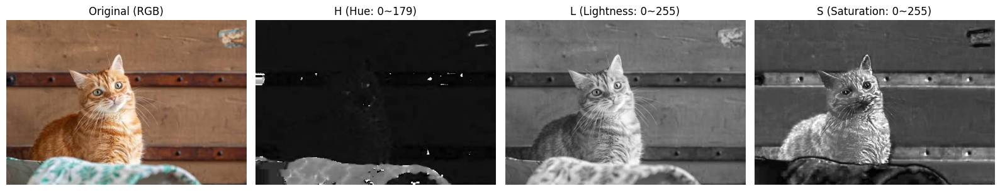

In [ ]:
import cv2
import matplotlib.pyplot as plt

# 1. 讀取圖片並轉為 HLS
img_bgr = cv2.imread("images.jpg")
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

# 轉換為 HLS 格式 (注意：OpenCV 的通道順序為 H, L, S)
img_hls = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HLS)
H, L, S = cv2.split(img_hls)

# 2. 用 Matplotlib 顯示原圖與各通道
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(img_rgb)
axes[0].set_title("Original (RGB)")

# H 通道：色彩角度 (0~179)
axes[1].imshow(H, cmap="gray")
axes[1].set_title("H (Hue: 0~179)")

# L 通道：光暗強度 (0~255，越白越亮)
axes[2].imshow(L, cmap="gray")
axes[2].set_title("L (Lightness: 0~255)")

# S 通道：鮮豔度 (0~255，越白越鮮豔，灰階處為黑)
axes[3].imshow(S, cmap="gray")
axes[3].set_title("S (Saturation: 0~255)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


## LAB 色彩空間
**CIELAB** 是由國際照明委員會（CIE）定義的色彩空間，旨在逼近人類的視覺感知。

### 1. LAB 的結構 (通道組成)
LAB 色彩空間將顏色分解為三個相互垂直的軸：
- **$L^*$ (亮度, Lightness)**：表示顏色的明暗程度。取值範圍通常從 $0$（純黑）到 $100$（純白）。
- **$a^*$ (紅-綠軸)**：正值（$+a^*$）表示偏紅/洋紅，負值（$-a^*$）表示偏綠。取值範圍通常在 $-128$ 到 $+127$ 之間。
- **$b^*$ (黃-藍軸)**：正值（$+b^*$）表示偏黃，負值（$-b^*$）表示偏藍。取值範圍通常在 $-128$ 到 $+127$ 之間。

---

### 2. LAB 的特點
- **感知均勻 (Perceptually Uniform)**：空間中兩個顏色的歐幾里得距離，與人眼感知的顏色差異成正比。
- **設備無關 (Device-Independent)**：不依賴於特定硬體設備（如螢幕或印表機）的顯示特性。
- **明暗與色彩分離**：亮度資訊完全集中在 $L^*$ 通道，色度資訊則在 $a^*$ 與 $b^*$ 通道，可獨立調整。
- **色差計算**：極度適合用於量化與計算顏色差異（$\Delta E$）。

---

### 3. 色差計算 ($\Delta E$)
當需要量化兩個顏色 $C_1 = (L_1, a_1, b_1)$ 與 $C_2 = (L_2, a_2, b_2)$ 之間的差異時，可使用最基礎的 CIE76 歐幾里得距離公式計算色差 $\Delta E^*_{ab}$：

$\Delta E^*_{ab} = \sqrt{(L_2 - L_1)^2 + (a_2 - a_1)^2 + (b_2 - b_1)^2}$

#### $\Delta E$ 數值與人眼感知的對應關係：
| $\Delta E$ 範圍 | 人眼視覺感受 |
| :--- | :--- |
| $\Delta E < 1$ | 肉眼幾乎無法分辨差異 |
| $1 < \Delta E < 2$ | 需由專業人士仔細比對才能察覺微小差異 |
| $2 < \Delta E < 3.5$ | 一般人經過觀察可以察覺出差異 |
| $\Delta E > 5$ | 明顯被視為兩種不同的顏色 |

---

### 4. 應用場景
1. **色彩校正 (Color Correction)**：在不影響影像亮度對比（$L^*$）的情況下，修正偏色問題。
2. **色彩匹配 (Color Matching)**：工業印刷、紡織品與塗料生產中的品質控管（比對標準色卡與產品的 $\Delta E$）。
3. **白平衡調整 (White Balance)**：透過平移 $a^*$ 與 $b^*$ 通道的數值來消除色偏。
4. **膚色檢測與圖像分割**：利用人類膚色在 $a^*$（偏紅）與 $b^*$（偏黃）通道上集中分佈的特性，排除光影（$L^*$）干擾進行人臉或手勢偵測。
5. **色彩空間轉換的中間站**：作為設備相關色彩空間（如 RGB 與 CMYK）轉換時的標準橋樑：

$RGB \rightarrow XYZ \rightarrow LAB \rightarrow XYZ \rightarrow CMYK$

shape = (371, 538, 3), dtype = uint8
a、b 共用色階: [-34, 34]


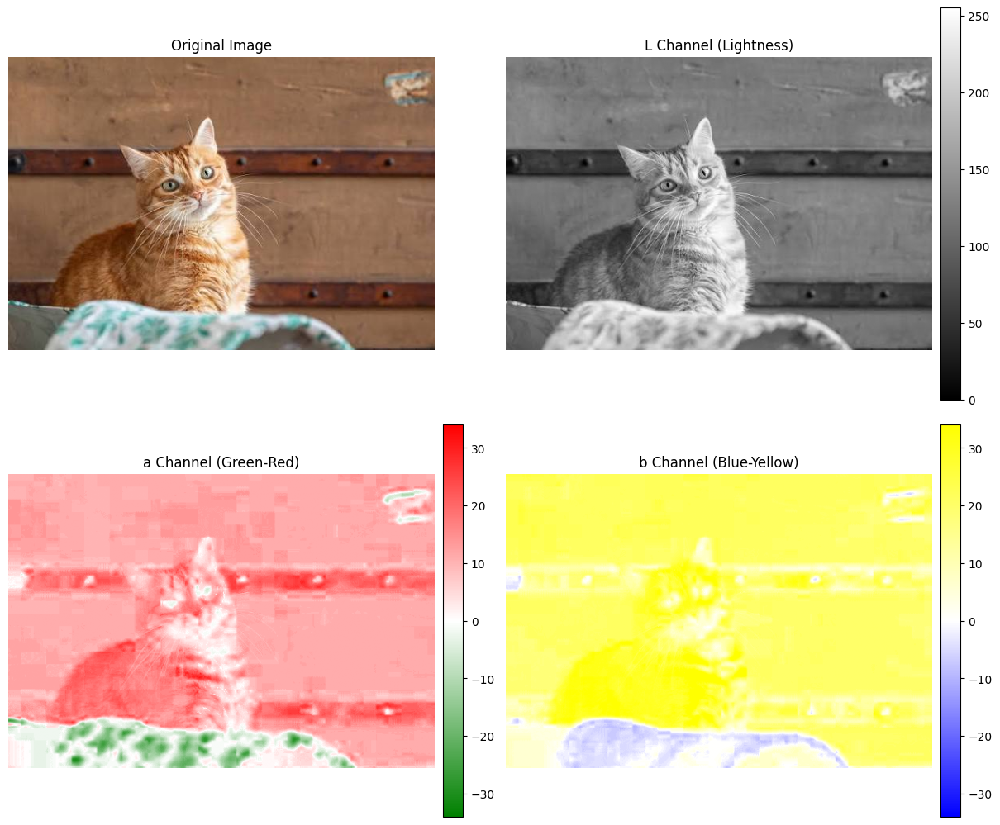

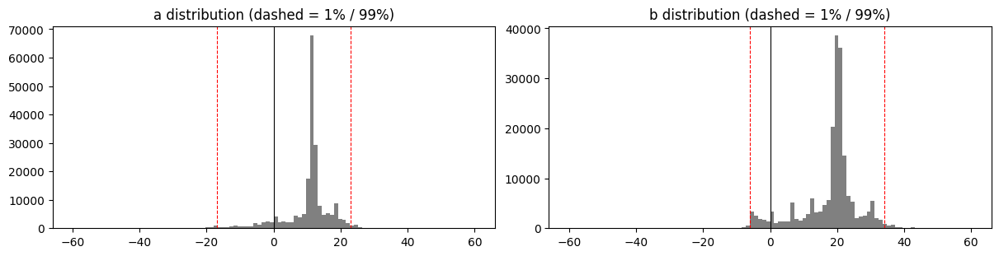

L channel range: [1, 255]
a channel range: [-31, 32]
b channel range: [-10, 50]


In [ ]:
# ============================================================
# BGR -> LAB 視覺化（L / a / b 通道）
# ============================================================
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# ---------- 設定 ----------
PATH       = "images.jpg"
PERCENTILE = 99     # 色階上限取 |a|、|b| 的第幾百分位
MIN_LIMIT  = 20     # 色階上限的下限，避免範圍被壓得太窄
SHOW_HIST  = True   # 是否額外畫出 a、b 的分布直方圖

# ---------- 1. 讀圖 ----------
img = cv2.imread(PATH)   # imread 是 BGR 順序
if img is None:
    raise FileNotFoundError(f"讀不到 {PATH}，請確認檔名與路徑")
print(f"shape = {img.shape}, dtype = {img.dtype}")

# ---------- 2. BGR -> LAB 並分離通道 ----------
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
l, a, b = cv2.split(cv2.cvtColor(img, cv2.COLOR_BGR2LAB))

# OpenCV 8-bit LAB：a、b 有 +128 偏移，還原成有正負的真實值
# 先轉 int16，避免 uint8 相減溢位
a = a.astype(np.int16) - 128
b = b.astype(np.int16) - 128

# ---------- 3. 色盤與色階 ----------
# 以 0 為中性色（白），兩端各代表一個色彩軸
cmap_a = LinearSegmentedColormap.from_list("green_red",   ["green", "white", "red"])
cmap_b = LinearSegmentedColormap.from_list("blue_yellow", ["blue",  "white", "yellow"])

# a、b 共用同一組對稱色階，兩通道的顏色深淺才能互相比較
lim = int(max(np.percentile(np.abs(a), PERCENTILE),
              np.percentile(np.abs(b), PERCENTILE)))
lim = max(lim, MIN_LIMIT)
print(f"a、b 共用色階: [{-lim}, {lim}]")

panels = [
    # (影像, 標題, colormap, imshow 參數)
    (img_rgb, "Original Image",          None,   {}),
    (l,       "L Channel (Lightness)",   "gray", dict(vmin=0,    vmax=255)),
    (a,       "a Channel (Green-Red)",   cmap_a, dict(vmin=-lim, vmax=lim)),
    (b,       "b Channel (Blue-Yellow)", cmap_b, dict(vmin=-lim, vmax=lim)),
]

# ---------- 4. 繪圖 ----------
# constrained_layout 會自動處理 colorbar 與標題，不會被切掉
fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)

for ax, (data, title, cmap, kwargs) in zip(axes.ravel(), panels):
    im = ax.imshow(data, cmap=cmap, **kwargs)
    ax.set_title(title)
    ax.axis("off")
    if cmap is not None:                         # 原圖不需要 colorbar
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)

plt.show()

# ---------- 5. 分布直方圖（協助判斷色階是否合適）----------
if SHOW_HIST:
    fig, axs = plt.subplots(1, 2, figsize=(12, 3), constrained_layout=True)
    for ax, ch, name in zip(axs, (a, b), ("a", "b")):
        ax.hist(ch.ravel(), bins=100, range=(-60, 60), color="gray")
        ax.axvline(0, color="k", lw=0.8)
        for q in (1, 99):
            ax.axvline(np.percentile(ch, q), color="r", ls="--", lw=0.8)
        ax.set_title(f"{name} distribution (dashed = 1% / 99%)")
    plt.show()

# ---------- 6. 數值範圍 ----------
for name, ch in zip("Lab", (l, a, b)):
    print(f"{name} channel range: [{ch.min()}, {ch.max()}]")


## YCrCb 色彩空間

**YCrCb** (通常寫作 **YCbCr** 或 $Y'C_bC_r$) 是一種廣泛應用於數位影像處理、視訊系統 (如電視廣播、DVD、藍光) 以及影像壓縮 (如 JPEG、MPEG) 的色彩空間。

與我們常見的 **RGB** (紅、綠、藍) 色彩空間不同，YCrCb 的核心概念是將「亮度資訊」與「色彩資訊」分開處理。

以下為您詳細解析 YCrCb 色彩空間的組成、原理、計算方式與應用場景：

## 1. YCrCb 的三個組成通道

在 YCrCb 色彩空間中，每個像素由三個數值表示：

*   **$Y$ (Luminance / Luma，明度/亮度)：**
    代表影像的灰階亮度資訊。如果只抽取出 $Y$ 通道並單獨顯示，你會看到一張完整的黑白灰階影像。
*   **$Cr$ (Chrominance Red，紅色色度差)：**
    代表紅色分量與亮度值 ($Y$) 之間的差異 (即 $R - Y$)。它反映了像素偏紅或偏青綠 (紅色的互補色) 的程度。
*   **$Cb$ (Chrominance Blue，藍色色度差)：**
    代表藍色分量與亮度值 ($Y$) 之間的差異 (即 $B - Y$)。它反映了像素偏藍或偏黃 (藍色的互補色) 的程度。

*(註：在許多電腦視覺函式庫如 OpenCV 中，通道順序常排列為 **YCrCb**；而在視訊標準文獻中，則常寫作 **YCbCr**，兩者本質完全相同，僅為 $Cr$ 與 $Cb$ 通道順序的對調。)*

## 2. 為什麼需要 YCrCb？ (生理與工程原因)

YCrCb 的設計完美結合了人類視覺系統 (Human Visual System, HVS) 的特性：

1.  **人眼對亮度比對色彩更敏感：**
    人類視網膜上的「視桿細胞」(負責感知明暗與輪廓) 數量遠多於「視錐細胞」(負責感知色彩)。因此，人眼對影像明暗細節 ($Y$) 非常敏銳，但對色彩變化 ($Cr$、$Cb$) 相對遲鈍。
2.  **有利於「色度抽樣」(Chroma Subsampling) 與資料壓縮：**
    既然人眼對色彩不敏感，工程師在儲存或傳輸影像時，會保留全部的 $Y$ 通道解析度，但刻意降低 $Cr$ 和 $Cb$ 的解析度 (例如常見的 **YUV 4:2:2** 或 **4:2:0** 格式)。這樣可以在**人眼幾乎察覺不到畫質下降**的前提下，大幅減少 30% 到 50% 的資料量。
3.  **向下相容黑白電視：**
    在早期彩色電視發展時，將訊號分為 $Y$ 與色度訊號，可以讓黑白電視只接收 $Y$ 訊號正常播放，而彩色電視則同時接收三個訊號還原色彩。

## 3. RGB 與 YCrCb 的轉換公式

YCrCb 並非一個絕對色彩空間，而是對 RGB 進行線性轉換後的編碼方式。不同的標準 (如標清電視 BT.601、高清電視 BT.709、或 JPEG 全範圍標準) 有不同的轉換係數。

以下以最常見的 **ITU-R BT.601 (及數位影像 8-bit 轉換，數值範圍 $0 \sim 255$)** 為例：

#### (1) 從 RGB 轉換為 YCrCb：
首先計算亮度 $Y$ (因為人眼對綠色最敏感，所以 $G$ 的權重最高，約佔 $58.7\%$)：

$Y = 0.299 R + 0.587 G + 0.114 B$

接著計算色度差 (加上 $128$ 是為了避免出現負數，將數值平移到 $0 \sim 255$ 的正整數範圍內)：

$Cr = (R - Y) \times 0.713 + 128 = 0.500 R - 0.419 G - 0.081 B + 128$

$Cb = (B - Y) \times 0.564 + 128 = -0.169 R - 0.331 G + 0.500 B + 128$

#### (2) 從 YCrCb 轉回 RGB：

$R = Y + 1.403 (Cr - 128)$

$G = Y - 0.714 (Cr - 128) - 0.344 (Cb - 128)$

$B = Y + 1.773 (Cb - 128)$

## 4. 在影像處理與電腦視覺中的常見應用

除了上述的 **JPEG 圖片壓縮** 與 **MPEG/H.264 視訊壓縮** 外，YCrCb 在影像演算法中也非常實用：

*   **膚色偵測 (Skin Detection)：**
    在 RGB 空間中，當環境光線變亮或變暗時，皮膚的 $R, G, B$ 數值會同時劇烈變化，很難設定閾值。但在 YCrCb 空間中，光線明暗主要只影響 $Y$，人類皮膚的色度則會穩定地聚集在特定的 $Cr$ 與 $Cb$ 範圍內 (例如常見經驗值：$133 \le Cr \le 173$ 且 $77 \le Cb \le 127$)。這使得人臉或手勢偵測變得非常容易。
*   **影像對比度增強 (如直方圖均衡化)：**
    如果想提高彩色照片的對比度，若直接對 $R, G, B$ 三個通道分別做直方圖均衡化，會導致嚴重的色彩失真 (偏色)。正確的做法是：**先轉為 YCrCb，只對 $Y$ (亮度) 通道進行增強，保持 $Cr, Cb$ 不變，最後再轉回 RGB**。
*   **陰影去除與光照不均處理：**
    透過分離 $Y$ 通道，演算法可以針對光照不均勻的部分進行補償，而不會破壞物體原本的顏色。

## 5. 常見混淆：YUV 與 YCbCr (YCrCb) 的差別？
在日常開發中，人們常把 **YUV** 和 **YCbCr** 當成同義詞混用，但嚴格來說：
*   **YUV** 主要用於**類比 (Analog)** 視訊訊號 (如舊式 PAL 制式電視)。
*   **YCbCr / YCrCb** 則是 YUV 經過縮放與偏移後，專門用於**數位 (Digital)** 視訊與影像的標準格式。


學到的範圍 (Y, Cr, Cb): [ 78 148  99] ~ [223 199 128]


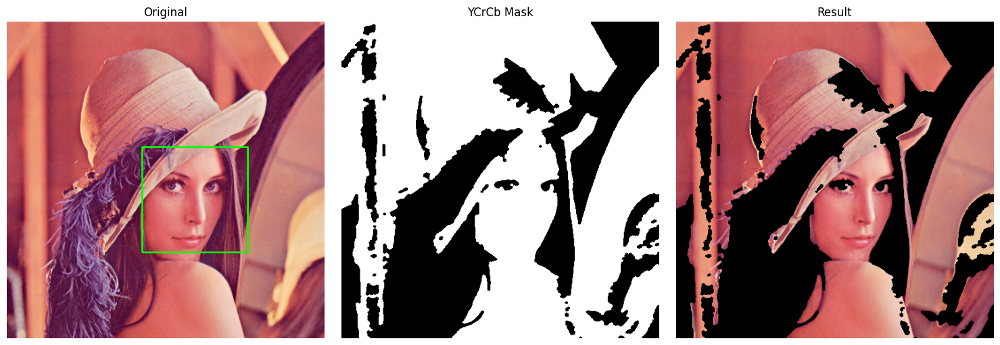

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("lena.png")
assert img is not None, "讀不到 lena.png"

# 1. 找臉
gray  = cv2.equalizeHist(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY))
cas   = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
faces = cas.detectMultiScale(gray, 1.1, 5)
assert len(faces) > 0, "找不到人臉"
x, y, w, h = max(faces, key=lambda f: f[2] * f[3])

# 2. 轉 YCrCb，並在臉頰/鼻子區域取樣（避開眼睛、頭髮、帽簷）
blur = cv2.GaussianBlur(img, (5, 5), 0)
ycc  = cv2.cvtColor(blur, cv2.COLOR_BGR2YCrCb)
roi  = ycc[y + int(h*0.40): y + int(h*0.80),
           x + int(w*0.25): x + int(w*0.75)].reshape(-1, 3)

p10, p90 = np.percentile(roi, [10, 90], axis=0)      # 順序: Y, Cr, Cb
pad   = np.array([40, 10, 10])
lower = np.clip(p10 - pad, 0, 255).astype(np.uint8)
upper = np.clip(p90 + pad, 0, 255).astype(np.uint8)
print("學到的範圍 (Y, Cr, Cb):", lower, "~", upper)

mask = cv2.inRange(ycc, lower, upper)

# 3. 去雜點
k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, k)
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN,  k)

# 4. 只保留與臉框重疊最多的連通區塊
n, lab = cv2.connectedComponents(mask)
score = np.bincount(lab[y:y+h, x:x+w].ravel(), minlength=n)
score[0] = 0
mask = np.where(lab == score.argmax(), 255, 0).astype(np.uint8)

# 5. 顯示
result = cv2.bitwise_and(img, img, mask=mask)
cv2.rectangle(img, (x, y), (x+w, y+h), (0, 255, 0), 2)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (title, data) in zip(axes, [
        ("Original", cv2.cvtColor(img, cv2.COLOR_BGR2RGB)),
        ("YCrCb Mask", mask),
        ("Result", cv2.cvtColor(result, cv2.COLOR_BGR2RGB))]):
    ax.imshow(data, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()


## CMYK 色彩空間
**CMYK** 是一種專門應用於**實體印刷**與**油墨輸出**的減法混色模式。與螢幕顯示使用的 RGB 模式不同，CMYK 是透過紙張反射光線、油墨吸收光線來呈現各種顏色。

---

## 1. 什麼是 CMYK？

CMYK 由四種油墨顏色的英文縮寫組成：

| 字母 | 英文名稱 | 中文名稱 | 說明 |
| :---: | :--- | :--- | :--- |
| **C** | **C**yan | 青色 / 靛藍 | 吸收紅光，反射綠光與藍光 |
| **M** | **M**agenta | 洋紅色 / 品紅 | 吸收綠光，反射紅光與藍光 |
| **Y** | **Y**ellow | 黃色 | 吸收藍光，反射紅光與綠光 |
| **K** | **K**ey (Black) | 黑色 | 關鍵版／校準版，提供深層對比與陰影 |

> **為什麼黑色使用「K」而不是「B」？**
> 1. 避免與 RGB 中的 **B（Blue，藍色）** 混淆。
> 2. 傳統印刷中，黑色通常是定位與校準其他三色網點的關鍵印版（**Key Plate**）。

---

## 2. 色彩原理：減法混色（Subtractive Color Mixing）

* **RGB（加法混色）**：應用於主動發光的媒介（如螢幕、電視、手機）。顏色疊加越多，光線越強越亮，$R + G + B = \text{白色}$。
* **CMYK（減法混色）**：應用於不發光的媒介（如紙張、畫布）。顏料會吸收（減去）特定光波，疊加越多油墨，光線被吸收得越多，顏色越深。
  * **C + M** = 藍色（Blue）
  * **M + Y** = 紅色（Red）
  * **C + Y** = 綠色（Green）
  * **C + M + Y** = 理論上為黑色，但實務上因油墨純度不足，混合後多為混濁的深褐色。

---

## 3. CMYK 的數值表示法

與 RGB 的數值範圍（$0 \sim 255$）不同，CMYK 通常採用 **百分比（$0\% \sim 100\%$）** 表示油墨的濃度或網點面積覆蓋率：

* **$0\%$**：該色油墨不上色（呈現紙張底色，通常為白）。
* **$100\%$**：該色油墨全滿（完全覆蓋）。

### 常見顏色配比範例

| 顏色外觀 | 顏色名稱 | C (%) | M (%) | Y (%) | K (%) | 用途與說明 |
| :---: | :--- | :---: | :---: | :---: | :---: | :--- |
| ⬛ | **單黑 (K100)** | 0 | 0 | 0 | 100 | 書籍、雜誌內文細字專用，避免套印重影 |
| 🖤 | **濃黑 (Rich Black)** | 30 | 30 | 30 | 100 | 用於大面積黑色背景，比單黑更深邃厚實 |
| 🟥 | **純紅** | 0 | 100 | 100 | 0 | 洋紅 + 黃 |
| 🟩 | **純綠** | 100 | 0 | 100 | 0 | 青色 + 黃 |
| 🟦 | **純藍** | 100 | 100 | 0 | 0 | 青色 + 洋紅 |
| 🟨 | **純黃** | 0 | 0 | 100 | 0 | 100% 黃墨 |
| 🟧 | **橙橘色** | 0 | 60 | 100 | 0 | 黃色加入部分洋紅 |
| ⬜ | **純白** | 0 | 0 | 0 | 0 | 不印任何油墨（依賴紙張白度） |

---

## 4. CMYK vs RGB 對比

| 比較項目 | CMYK 模式 | RGB 模式 |
| :--- | :--- | :--- |
| **混色原理** | 減法混色（Subtractive） | 加法混色（Additive） |
| **主要媒介** | 書籍、宣傳單、海報、包裝印刷品 | 電腦螢幕、手機螢幕、相機、投影機 |
| **色域範圍（Gamut）** | 較小（難以呈現過度鮮豔的螢光感） | 較大（能呈現高飽和度、極度亮麗的顏色） |
| **數值範圍** | 各通道 $0\% \sim 100\%$ | 各通道 $0 \sim 255$ |
| **混合全滿** | 接近黑色（需 K 墨增強深度） | 純白色 |

---

## 5. 印刷與平面設計實務注意事項

1. **設計初期確定色彩模式**
   * 若作品最終需實體印刷，請務必在 Illustrator、Photoshop 或 InDesign 建立檔案時就選定為 **CMYK 模式**。
   * 若以 RGB 模式設計後再硬轉 CMYK，高飽和色彩（特別是亮綠色、螢光粉、青藍色）會明顯發灰、變暗。

2. **內文細小文字切忌「四色黑」**
   * 內文文字與小字應設為 **C:0 M:0 Y:0 K:100**（單黑）。
   * 若設為四色黑（例如四色均有數值），印刷套印只要稍微偏位，文字邊緣就會產生模糊重影。

3. **總墨量上限（Total Area Coverage, TAC）**
   * 四色數值加總不宜超過 **$280\% \sim 320\%$**（依紙張材質如銅版紙、模造紙而定）。
   * 超過墨量極限會導致油墨過厚、不易乾燥，容易造成印件互相沾黏（背印）或產生墨污。


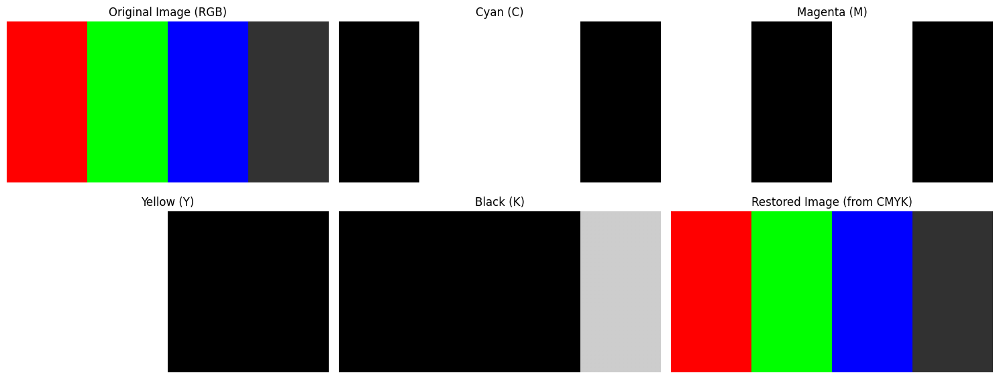

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np


def bgr_to_cmyk(img_bgr):
    # 1. 將 BGR 轉為 0.0 ~ 1.0 的浮點數
    bgr_norm = img_bgr.astype(np.float32) / 255.0
    B, G, R = cv2.split(bgr_norm)

    # 2. 計算 K 通道 (1 - max(R, G, B))
    K = 1.0 - np.maximum(np.maximum(R, G), B)

    # 3. 避免除以 0 (當 K=1 即純黑時，分母設為 1，分子本身也會變成 0)
    denom = 1.0 - K
    denom[denom == 0] = 1.0

    # 4. 計算 C, M, Y 通道
    C = (1.0 - R - K) / denom
    M = (1.0 - G - K) / denom
    Y = (1.0 - B - K) / denom

    # 5. 將範圍轉回 0 ~ 255 的 uint8 格式
    C_uint8 = (C * 255).astype(np.uint8)
    M_uint8 = (M * 255).astype(np.uint8)
    Y_uint8 = (Y * 255).astype(np.uint8)
    K_uint8 = (K * 255).astype(np.uint8)

    # 合併為 4 通道的 CMYK 矩陣 (H, W, 4)
    cmyk = cv2.merge([C_uint8, M_uint8, Y_uint8, K_uint8])
    return cmyk, (C_uint8, M_uint8, Y_uint8, K_uint8)


def cmyk_to_bgr(cmyk):
    # 將 0~255 轉回 0.0~1.0
    C, M, Y, K = cv2.split(cmyk.astype(np.float32) / 255.0)

    # 反向公式計算 R, G, B
    R = (1.0 - C) * (1.0 - K)
    G = (1.0 - M) * (1.0 - K)
    B = (1.0 - Y) * (1.0 - K)

    bgr = cv2.merge([B, G, R])
    return (bgr * 255).astype(np.uint8)


# --- 測試執行 ---
if __name__ == "__main__":
    # 建立一張測試圖 (或改用 cv2.imread("your_image.jpg") 讀取)
    img = np.zeros((200, 400, 3), dtype=np.uint8)
    img[:, 0:100] = [0, 0, 255]  # 紅 (BGR)
    img[:, 100:200] = [0, 255, 0]  # 綠
    img[:, 200:300] = [255, 0, 0]  # 藍
    img[:, 300:400] = [50, 50, 50]  # 深灰

    # 轉換為 CMYK
    cmyk_img, (C, M, Y, K) = bgr_to_cmyk(img)

    # 測試將 CMYK 轉回 BGR
    restored_bgr = cmyk_to_bgr(cmyk_img)

    # --- 使用 Matplotlib 繪製 2x3 網格圖 ---
    fig, axes = plt.subplots(2, 3, figsize=(15, 6))

    # 1. 原始圖片 (需將 BGR 轉為 RGB 才能正確顯示顏色)
    axes[0, 0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[0, 0].set_title("Original Image (RGB)")

    # 2. C, M, Y, K 各通道灰階圖 (越白代表濃度越高，需指定 vmin=0, vmax=255 避免自動縮放對比)
    axes[0, 1].imshow(C, cmap="gray", vmin=0, vmax=255)
    axes[0, 1].set_title("Cyan (C)")

    axes[0, 2].imshow(M, cmap="gray", vmin=0, vmax=255)
    axes[0, 2].set_title("Magenta (M)")

    axes[1, 0].imshow(Y, cmap="gray", vmin=0, vmax=255)
    axes[1, 0].set_title("Yellow (Y)")

    axes[1, 1].imshow(K, cmap="gray", vmin=0, vmax=255)
    axes[1, 1].set_title("Black (K)")

    # 3. 還原後的圖片 (同樣需將 BGR 轉為 RGB)
    axes[1, 2].imshow(cv2.cvtColor(restored_bgr, cv2.COLOR_BGR2RGB))
    axes[1, 2].set_title("Restored Image (from CMYK)")

    # 隱藏座標軸刻度並自動調整間距
    for ax in axes.flat:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


## OpenCV 支援的色彩空間

In [ ]:
import cv2
# 列出所有可用的色彩空間轉換
color_conversions = [attr for attr in dir(cv2) if attr.startswith('COLOR_')]

print(f"Total color space conversions available: {len(color_conversions)}\n")
print("Common conversions:")

common = [
    'COLOR_BGR2RGB', 'COLOR_RGB2BGR',
    'COLOR_BGR2GRAY', 'COLOR_GRAY2BGR',
    'COLOR_BGR2HSV', 'COLOR_HSV2BGR',
    'COLOR_BGR2HLS', 'COLOR_HLS2BGR'
    'COLOR_BGR2LAB', 'COLOR_LAB2BGR',
    'COLOR_BGR2YCrCb','COLOR_YCrCb2BGR',
]

for i, conv in enumerate(common, 1):
    print(f"{i:2d}. cv2.{conv}")

Total color space conversions available: 374

Common conversions:
 1. cv2.COLOR_BGR2RGB
 2. cv2.COLOR_RGB2BGR
 3. cv2.COLOR_BGR2GRAY
 4. cv2.COLOR_GRAY2BGR
 5. cv2.COLOR_BGR2HSV
 6. cv2.COLOR_HSV2BGR
 7. cv2.COLOR_BGR2HLS
 8. cv2.COLOR_HLS2BGRCOLOR_BGR2LAB
 9. cv2.COLOR_LAB2BGR
10. cv2.COLOR_BGR2YCrCb
11. cv2.COLOR_YCrCb2BGR


# 🌈 4. 偽彩色轉換 (Pseudocolor / Colormaps)

## cv2.applyColorMap 應用


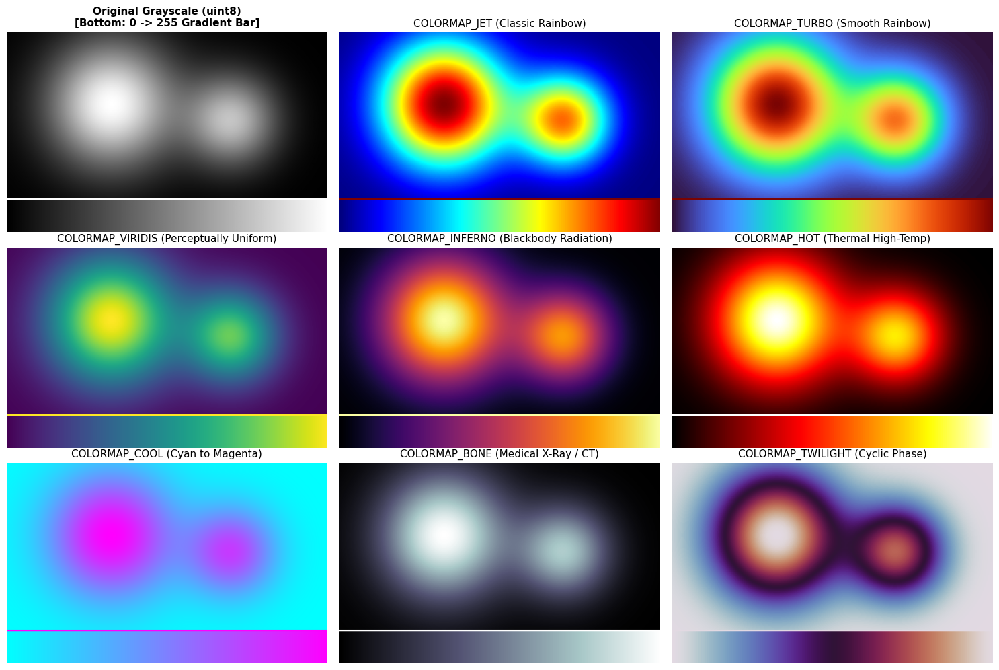

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 產生合成測試圖 (上半部為雙峰熱源，下半部為 0~255 線性色階條)
H, W = 250, 400
y, x = np.ogrid[0:H, 0:W]

g1 = np.exp(-((x - 130)**2 + (y - 90)**2) / (2 * 55**2))
g2 = 0.75 * np.exp(-((x - 280)**2 + (y - 110)**2) / (2 * 40**2))
field = g1 + g2

# 正規化至 uint8 [0, 255]
gray_img = cv2.normalize(field, None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)

# 在底部 40 px 加上 0~255 標準漸層條 (Colorbar 對照用)
gradient_bar = np.linspace(0, 255, W, dtype=np.uint8)
gray_img[H-40:, :] = gradient_bar
gray_img[H-42:H-40, :] = 255  # 白色分隔線

# 2. 挑選 8 個最具代表性的 Colormaps (英文標題)
colormaps = [
    ("COLORMAP_JET (Classic Rainbow)", cv2.COLORMAP_JET),
    ("COLORMAP_TURBO (Smooth Rainbow)", cv2.COLORMAP_TURBO),
    ("COLORMAP_VIRIDIS (Perceptually Uniform)", cv2.COLORMAP_VIRIDIS),
    ("COLORMAP_INFERNO (Blackbody Radiation)", cv2.COLORMAP_INFERNO),
    ("COLORMAP_HOT (Thermal High-Temp)", cv2.COLORMAP_HOT),
    ("COLORMAP_COOL (Cyan to Magenta)", cv2.COLORMAP_COOL),
    ("COLORMAP_BONE (Medical X-Ray / CT)", cv2.COLORMAP_BONE),
    ("COLORMAP_TWILIGHT (Cyclic Phase)", cv2.COLORMAP_TWILIGHT),
]

# 3. 繪圖比較
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.ravel()

axes[0].imshow(gray_img, cmap='gray', vmin=0, vmax=255)
axes[0].set_title("Original Grayscale (uint8)\n[Bottom: 0 -> 255 Gradient Bar]", fontsize=11, fontweight='bold')
axes[0].axis('off')

for idx, (name, cmap_code) in enumerate(colormaps, start=1):
    pseudo_bgr = cv2.applyColorMap(gray_img, cmap_code)
    pseudo_rgb = cv2.cvtColor(pseudo_bgr, cv2.COLOR_BGR2RGB)

    axes[idx].imshow(pseudo_rgb)
    axes[idx].set_title(name, fontsize=11)
    axes[idx].axis('off')

plt.tight_layout()
plt.show()


## AI 注意力熱力圖疊加 (Grad-CAM Heatmap Overlay)

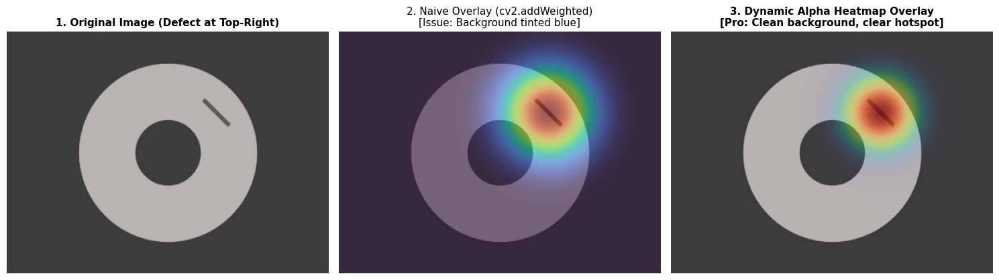

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 建立一張模擬的待檢測工業零件底圖 (BGR)
H, W = 300, 400
base_img = np.zeros((H, W, 3), dtype=np.uint8)
base_img[:] = (60, 60, 60)  # 深灰背景
# 畫一個金屬圓盤零件與內孔
cv2.circle(base_img, (200, 150), 110, (180, 180, 185), -1, cv2.LINE_AA)
cv2.circle(base_img, (200, 150), 40, (60, 60, 60), -1, cv2.LINE_AA)
# 模擬右上角有一道微小裂痕瑕疵
cv2.line(base_img, (245, 85), (275, 115), (90, 90, 95), 3, cv2.LINE_AA)

# 2. 模擬 AI 模型輸出的瑕疵機率圖 (float32, 0.0 ~ 1.0)，鎖定在 (260, 100) 裂痕處
y, x = np.ogrid[0:H, 0:W]
prob_map = np.exp(-((x - 260)**2 + (y - 100)**2) / (2 * 35**2)).astype(np.float32)

# 3. 轉為 uint8 [0, 255] 並產生 TURBO 偽彩色熱力圖
prob_u8 = (prob_map * 255).astype(np.uint8)
heatmap_bgr = cv2.applyColorMap(prob_u8, cv2.COLORMAP_TURBO)

# --- 方法 A：直接全圖 cv2.addWeighted 疊加 (常見做法，但背景會泛藍) ---
overlay_naive = cv2.addWeighted(base_img, 0.5, heatmap_bgr, 0.5, 0)

# --- 方法 B：進階 Alpha 隨熱度動態混合 (背景保持原色，只凸顯高溫區！) ---
# 利用 prob_map (0.0~1.0) 作為每個像素的透明度權重 alpha
alpha = (prob_map * 0.75)[..., np.newaxis]  # 最大不透明度 0.75，擴展為 (H, W, 1)
overlay_pro = (base_img * (1.0 - alpha) + heatmap_bgr * alpha).astype(np.uint8)

# 4. 視覺化對比 (英文標題避免 Colab Matplotlib 亂碼)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].imshow(cv2.cvtColor(base_img, cv2.COLOR_BGR2RGB))
axes[0].set_title("1. Original Image (Defect at Top-Right)", fontsize=11, fontweight='bold')

axes[1].imshow(cv2.cvtColor(overlay_naive, cv2.COLOR_BGR2RGB))
axes[1].set_title("2. Naive Overlay (cv2.addWeighted)\n[Issue: Background tinted blue]", fontsize=11)

axes[2].imshow(cv2.cvtColor(overlay_pro, cv2.COLOR_BGR2RGB))
axes[2].set_title("3. Dynamic Alpha Heatmap Overlay\n[Pro: Clean background, clear hotspot]", fontsize=11, fontweight='bold')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()


## 自訂專屬偽彩色盤 (Custom LUT Colormap)

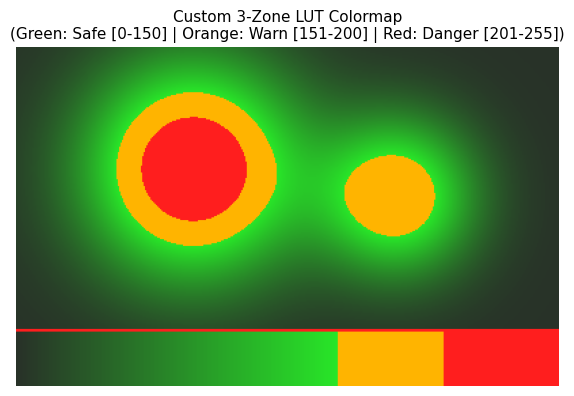

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 建立自訂的 (256, 1, 3) BGR 色盤查找表 (LUT)
custom_lut = np.zeros((256, 1, 3), dtype=np.uint8)

# 區段 1 [0 ~ 150]：安全區 (深綠 -> 亮綠)
for i in range(0, 151):
    g_val = int(50 + (i / 150.0) * 180)
    custom_lut[i, 0] = (40, g_val, 40)       # BGR

# 區段 2 [151 ~ 200]：警戒區 (亮黃橘色)
custom_lut[151:201, 0] = (0, 180, 255)       # BGR

# 區段 3 [201 ~ 255]：危險超標區 (鮮紅色)
custom_lut[201:256, 0] = (30, 30, 255)       # BGR

# 2. 套用至前面的測試灰階圖 gray_img
custom_colored_bgr = cv2.applyColorMap(gray_img, custom_lut)

# 3. 顯示結果 (英文標題)
plt.figure(figsize=(7, 4.5))
plt.imshow(cv2.cvtColor(custom_colored_bgr, cv2.COLOR_BGR2RGB))
plt.title("Custom 3-Zone LUT Colormap\n(Green: Safe [0-150] | Orange: Warn [151-200] | Red: Danger [201-255])", fontsize=11)
plt.axis('off')
plt.show()

## 熱力圖、紅外線夜視與深度影像視覺化（JET, VIRIDIS, INFERNO）


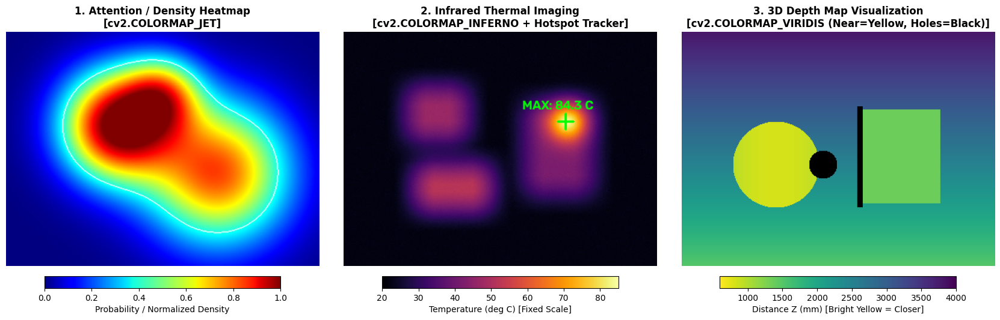

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 設定畫布大小，使用 np.mgrid 產生完整的 (H, W) 2D 座標矩陣
H, W = 300, 400
y, x = np.mgrid[0:H, 0:W]

# =========================================================================
# 場景 1：熱力圖 (Heatmap - COLORMAP_JET)
# 模擬：商場人流駐留密度 / 視覺注意力分佈 (數值範圍 0.0 ~ 1.0)
# =========================================================================
hotspot1 = 1.0 * np.exp(-((x - 140)**2 + (y - 120)**2) / (2 * 50**2))
hotspot2 = 0.8 * np.exp(-((x - 270)**2 + (y - 180)**2) / (2 * 65**2))
hotspot3 = 0.5 * np.exp(-((x - 200)**2 + (y - 80)**2) / (2 * 35**2))
heatmap_raw = np.clip(hotspot1 + hotspot2 + hotspot3, 0.0, 1.0)

# 轉為 uint8 [0, 255] 並套用 COLORMAP_JET
heatmap_u8 = (heatmap_raw * 255).astype(np.uint8)
jet_bgr = cv2.applyColorMap(heatmap_u8, cv2.COLORMAP_JET)
# 在熱力圖上疊加等高線 (Contour Lines)，增加工程專業感
contours, _ = cv2.findContours((heatmap_u8 > 100).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cv2.drawContours(jet_bgr, contours, -1, (255, 255, 255), 1, cv2.LINE_AA)
jet_rgb = cv2.cvtColor(jet_bgr, cv2.COLOR_BGR2RGB)


# =========================================================================
# 場景 2：紅外線熱成像 (Thermal Imaging - COLORMAP_INFERNO)
# 模擬：變電箱/電路板溫度場 (°C)，環境 22°C，正常元件 45°C，過熱短路點 82°C
# =========================================================================
np.random.seed(42)
thermal_temp = np.full((H, W), 22.0, dtype=np.float32)  # 環境室溫 22°C
# 模擬三個發熱晶片區域 (長方形熱源 + 高斯擴散)
chip_mask = np.zeros((H, W), dtype=np.float32)
chip_mask[70:140, 80:160] = 25.0   # 晶片 A (+25°C -> ~47°C)
chip_mask[170:230, 90:190] = 30.0  # 晶片 B (+30°C -> ~52°C)
chip_mask[90:210, 230:320] = 20.0  # 晶片 C (+20°C -> ~42°C)
thermal_temp += cv2.GaussianBlur(chip_mask, (51, 51), 18)

# 模擬晶片 C 右上角發生局部短路過熱 (高達 ~82°C)
overheat = 42.0 * np.exp(-((x - 285)**2 + (y - 115)**2) / (2 * 18**2))
# 加入紅外線感測器微小的熱雜訊 (Thermal Noise)
noise = np.random.normal(0, 0.4, (H, W)).astype(np.float32)
thermal_temp = (thermal_temp + overheat + noise).astype(np.float32)

# 【關鍵技巧】固定物理溫度量程 (T_min = 20°C, T_max = 85°C) 轉為 uint8
T_min, T_max = 20.0, 85.0
thermal_u8 = np.clip((thermal_temp - T_min) / (T_max - T_min) * 255.0, 0, 255).astype(np.uint8)
inferno_bgr = cv2.applyColorMap(thermal_u8, cv2.COLORMAP_INFERNO)

# 找出全圖最高溫座標 (cv2.minMaxLoc)，並標註十字準星與溫度讀數
min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(thermal_temp)
cv2.drawMarker(inferno_bgr, max_loc, (0, 255, 0), cv2.MARKER_CROSS, 20, 2)
cv2.putText(inferno_bgr, f"MAX: {max_val:.1f} C", (max_loc[0] - 55, max_loc[1] - 15),
            cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 255, 0), 2, cv2.LINE_AA)
inferno_rgb = cv2.cvtColor(inferno_bgr, cv2.COLOR_BGR2RGB)


# =========================================================================
# 場景 3：深度影像視覺化 (Depth Map - COLORMAP_VIRIDIS)
# 模擬：ToF / 雙目深度相機 (單位 mm，範圍 500mm ~ 4000mm，0 代表無效破洞)
# =========================================================================
# 背景為由近(底部 1500mm)到遠(頂部 3800mm)的地面斜坡
depth_mm = np.linspace(3800, 1500, H)[:, np.newaxis] * np.ones((1, W), dtype=np.float32)

# 前景物體 1：左側近處圓柱體 (距離約 800mm ~ 950mm 立體曲面)
cyl_mask = ((x - 120)**2 + (y - 170)**2) < 55**2
depth_mm[cyl_mask] = 800.0 + 150.0 * ((x[cyl_mask] - 120) / 55.0)**2

# 前景物體 2：右側中距離方盒 (距離 1350mm)
depth_mm[100:220, 230:330] = 1350.0

# 模擬深度相機常見的「無效像素破洞 (Invalid Holes = 0)」(例如物體邊緣陰影或反光面)
invalid_mask = (((x - 180)**2 + (y - 170)**2) < 18**2) | ((y > 95) & (y < 225) & (x >= 224) & (x <= 230))
depth_mm[invalid_mask] = 0.0

# 【關鍵技巧】反轉深度映射 (近亮黃 255，遠深紫 0) + 無效點強制塗黑
D_min, D_max = 600.0, 4000.0
valid_mask = (depth_mm > 0)
# 距離越近 (接近 D_min)，正規化值越接近 255 (亮黃色)
depth_inv_u8 = np.clip((D_max - depth_mm) / (D_max - D_min) * 255.0, 0, 255).astype(np.uint8)
viridis_bgr = cv2.applyColorMap(depth_inv_u8, cv2.COLORMAP_VIRIDIS)
# 將無效深度像素 (depth == 0) 強制設為純黑 (0, 0, 0)
viridis_bgr[~valid_mask] = (0, 0, 0)
viridis_rgb = cv2.cvtColor(viridis_bgr, cv2.COLOR_BGR2RGB)


# =========================================================================
# 視覺化展示 (搭配對應的物理量程 Colorbar)
# =========================================================================
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# 1. 繪製 Heatmap (JET)
axes[0].imshow(jet_rgb)
axes[0].set_title("1. Attention / Density Heatmap\n[cv2.COLORMAP_JET]", fontsize=12, fontweight='bold')
axes[0].axis('off')
sm0 = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=0.0, vmax=1.0))
cbar0 = fig.colorbar(sm0, ax=axes[0], fraction=0.046, pad=0.04, orientation='horizontal')
cbar0.set_label("Probability / Normalized Density", fontsize=10)

# 2. 繪製 Thermal Image (INFERNO)
axes[1].imshow(inferno_rgb)
axes[1].set_title("2. Infrared Thermal Imaging\n[cv2.COLORMAP_INFERNO + Hotspot Tracker]", fontsize=12, fontweight='bold')
axes[1].axis('off')
sm1 = plt.cm.ScalarMappable(cmap='inferno', norm=plt.Normalize(vmin=T_min, vmax=T_max))
cbar1 = fig.colorbar(sm1, ax=axes[1], fraction=0.046, pad=0.04, orientation='horizontal')
cbar1.set_label("Temperature (deg C) [Fixed Scale]", fontsize=10)

# 3. 繪製 Depth Map (VIRIDIS)
axes[2].imshow(viridis_rgb)
axes[2].set_title("3. 3D Depth Map Visualization\n[cv2.COLORMAP_VIRIDIS (Near=Yellow, Holes=Black)]", fontsize=12, fontweight='bold')
axes[2].axis('off')
# Colorbar 反轉以對應「左近(亮黃) / 右遠(深紫)」或「近亮遠暗」
sm2 = plt.cm.ScalarMappable(cmap='viridis_r', norm=plt.Normalize(vmin=D_min, vmax=D_max))
cbar2 = fig.colorbar(sm2, ax=axes[2], fraction=0.046, pad=0.04, orientation='horizontal')
cbar2.set_label("Distance Z (mm) [Bright Yellow = Closer]", fontsize=10)

plt.tight_layout()
plt.show()


# 🚀 5. 實戰演練 (Practical Projects)


## 實作 1：HSV 雙向滑桿調試器與即時目標追蹤


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

# =========================================================================
# 1. 建立具有真實光影漸層與反光的「多色撞球/工業產線」合成測試場景
# =========================================================================
def create_test_scene(H=320, W=480):
    scene = np.zeros((H, W, 3), dtype=np.uint8)
    # 帶有微弱漸層與雜訊的灰暗桌面背景
    y_grid, x_grid = np.mgrid[0:H, 0:W]
    bg_val = (45 + 20 * (y_grid / H) + np.random.normal(0, 3, (H, W))).clip(0, 255).astype(np.uint8)
    scene[:] = bg_val[..., np.newaxis]

    # 定義 5 顆不同顏色的立體球體: (名稱, 中心(x,y), 半徑, BGR主色)
    balls = [
        ("Red",    (95, 105),  48, (30, 25, 230)),   # 紅球 (H ~ 0-5 & 175-179)
        ("Yellow", (240, 95),  44, (20, 220, 240)),  # 黃球 (H ~ 25-32)
        ("Green",  (385, 110), 46, (45, 195, 40)),   # 綠球 (H ~ 55-65)
        ("Blue",   (160, 225), 50, (235, 110, 20)),  # 藍球 (H ~ 105-115)
        ("Purple", (325, 225), 45, (200, 40, 180)),  # 紫球 (H ~ 145-155)
    ]

    # 繪製具有 3D 明暗立體感 (Shading) 與高光反光點 (Specular Highlight) 的球體
    for name, (cx, cy), r, bgr in balls:
        dist = np.sqrt((x_grid - cx)**2 + (y_grid - cy)**2)
        mask = dist <= r
        # 模擬左上角光源照射的 3D 球面明暗係數 (0.35 ~ 1.15)
        light = np.clip(1.15 - 0.75 * np.sqrt((x_grid - (cx - r*0.3))**2 + (y_grid - (cy - r*0.3))**2) / r, 0.3, 1.15)
        for c in range(3):
            scene[mask, c] = np.clip(bgr[c] * light[mask], 0, 255).astype(np.uint8)

        # 加上中心高光白點 (測試學生是否理解高光區 S 飽和度會下降)
        cv2.circle(scene, (int(cx - r*0.3), int(cy - r*0.3)), int(r*0.18), (245, 245, 245), -1, cv2.LINE_AA)
        # 加上文字標籤
        cv2.putText(scene, name, (cx - 25, cy + r + 20), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (200, 200, 200), 1, cv2.LINE_AA)

    # 故意在背景撒一些細小的彩色噪點 (測試形態學去雜訊的效果)
    np.random.seed(7)
    for _ in range(35):
        nx, ny = np.random.randint(10, W-10), np.random.randint(10, H-10)
        rand_bgr = [int(c) for c in np.random.randint(50, 250, 3)]
        cv2.circle(scene, (nx, ny), 2, rand_bgr, -1)

    return scene

base_bgr = create_test_scene()
base_hsv = cv2.cvtColor(base_bgr, cv2.COLOR_BGR2HSV)

# 預先產生一條 0~179 的標準 Hue 色相參考條 (方便學生對照數值與顏色)
hue_bar_hsv = np.zeros((25, 180, 3), dtype=np.uint8)
hue_bar_hsv[:, :, 0] = np.arange(180)[np.newaxis, :]  # H: 0 ~ 179
hue_bar_hsv[:, :, 1] = 255                            # S: 255
hue_bar_hsv[:, :, 2] = 255                            # V: 255
hue_bar_rgb = cv2.cvtColor(hue_bar_hsv, cv2.COLOR_HSV2RGB)

# =========================================================================
# 2. 建立互動式控制面板與核心追蹤函式
# =========================================================================
preset_dict = {
    "Custom (Manual Drag)": None,
    "Track Blue Ball (H: 100~125)":   ((100, 125), (80, 255), (50, 255), False),
    "Track Green Ball (H: 40~80)":    ((40, 80),   (70, 255), (50, 255), False),
    "Track Yellow Ball (H: 20~35)":   ((20, 35),   (80, 255), (60, 255), False),
    "Track Purple Ball (H: 140~165)": ((140, 165), (70, 255), (50, 255), False),
    "Track Red Ball (Wrap-Around!)":  ((0, 10),    (80, 255), (60, 255), True),
}

# 定義雙向範圍滑桿 (IntRangeSlider)
preset_menu = widgets.Dropdown(options=list(preset_dict.keys()), value="Track Blue Ball (H: 100~125)", description="Preset:")
h_slider = widgets.IntRangeSlider(value=[100, 125], min=0, max=179, step=1, description='Hue (H):', continuous_update=False, layout=widgets.Layout(width='500px'))
s_slider = widgets.IntRangeSlider(value=[80, 255],  min=0, max=255, step=1, description='Sat (S):', continuous_update=False, layout=widgets.Layout(width='500px'))
v_slider = widgets.IntRangeSlider(value=[50, 255],  min=0, max=255, step=1, description='Val (V):', continuous_update=False, layout=widgets.Layout(width='500px'))
red_wrap_chk = widgets.Checkbox(value=False, description='Enable Red Wrap-Around (+ H: 170~179)')
morph_chk = widgets.Checkbox(value=True, description='Apply Morphology Denoising (Open + Close)')

# 當下拉選單改變時，自動更新滑桿位置
def on_preset_change(change):
    val = preset_dict[change['new']]
    if val is not None:
        h_slider.value, s_slider.value, v_slider.value, red_wrap_chk.value = val

preset_menu.observe(on_preset_change, names='value')

def update_tracker(h_range, s_range, v_range, red_wrap, use_morph):
    h_min, h_max = h_range
    s_min, s_max = s_range
    v_min, v_max = v_range

    # 1. 建立 HSV 上下界並執行 cv2.inRange
    lower1 = np.array([h_min, s_min, v_min], dtype=np.uint8)
    upper1 = np.array([h_max, s_max, v_max], dtype=np.uint8)
    mask = cv2.inRange(base_hsv, lower1, upper1)

    # 若勾選「紅色跨界模式」，額外合併 H: 170~179 區間
    if red_wrap:
        lower2 = np.array([170, s_min, v_min], dtype=np.uint8)
        upper2 = np.array([179, s_max, v_max], dtype=np.uint8)
        mask2 = cv2.inRange(base_hsv, lower2, upper2)
        mask = cv2.bitwise_or(mask, mask2)

    # 2. 形態學開運算(去背景噪點) + 閉運算(補球面高光破洞)
    if use_morph:
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

    # 3. 利用 Mask 摳出目標顏色區域 (Bitwise-AND)
    segmented_bgr = cv2.bitwise_and(base_bgr, base_bgr, mask=mask)

    # 4. 尋找輪廓並在原圖繪製追蹤框 (Bounding Box) 與中心點 (Centroid)
    track_bgr = base_bgr.copy()
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    detected_count = 0
    for cnt in contours:
        area = cv2.contourArea(cnt)
        if area > 300:  # 過濾面積太小的殘留雜訊
            detected_count += 1
            x, y, w, h = cv2.boundingRect(cnt)
            cx, cy = x + w // 2, y + h // 2
            # 畫綠色追蹤外框與十字準星
            cv2.rectangle(track_bgr, (x, y), (x + w, y + h), (0, 255, 0), 2)
            cv2.drawMarker(track_bgr, (cx, cy), (0, 255, 0), cv2.MARKER_CROSS, 16, 2)
            cv2.putText(track_bgr, f"Target ({cx},{cy})", (x - 10, y - 10),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2, cv2.LINE_AA)

    # 5. 視覺化呈現 (3 張主圖 + 底部 Hue 色相範圍指示條)
    fig = plt.figure(figsize=(16, 5.5))
    gs = fig.add_gridspec(2, 3, height_ratios=[5, 0.6], hspace=0.3)

    ax0 = fig.add_subplot(gs[0, 0])
    ax0.imshow(cv2.cvtColor(track_bgr, cv2.COLOR_BGR2RGB))
    ax0.set_title(f"1. Live Color Tracking (Detected: {detected_count})", fontsize=12, fontweight='bold')
    ax0.axis('off')

    ax1 = fig.add_subplot(gs[0, 1])
    ax1.imshow(mask, cmap='gray', vmin=0, vmax=255)
    title_wrap = " + [170,179]" if red_wrap else ""
    ax1.set_title(f"2. Binary Mask (cv2.inRange)\nH:[{h_min},{h_max}]{title_wrap}, S:[{s_min},{s_max}], V:[{v_min},{v_max}]", fontsize=11)
    ax1.axis('off')

    ax2 = fig.add_subplot(gs[0, 2])
    ax2.imshow(cv2.cvtColor(segmented_bgr, cv2.COLOR_BGR2RGB))
    ax2.set_title("3. Extracted Object (cv2.bitwise_and)", fontsize=12, fontweight='bold')
    ax2.axis('off')

    # 底部橫跨三欄的 Hue Scale 指示器，標示目前選中的 H 範圍
    ax_bar = fig.add_subplot(gs[1, :])
    bar_display = hue_bar_rgb.copy()
    # 將未選中的 Hue 區段變暗，凸顯目前滑桿選中的色相範圍
    active_h = np.zeros(180, dtype=bool)
    active_h[h_min:h_max+1] = True
    if red_wrap:
        active_h[170:180] = True
    bar_display[:, ~active_h, :] = (bar_display[:, ~active_h, :] * 0.25).astype(np.uint8)

    ax_bar.imshow(bar_display, aspect='auto', extent=[0, 179, 0, 1])
    ax_bar.set_yticks([])
    ax_bar.set_xticks(np.arange(0, 180, 15))
    ax_bar.set_xlabel("OpenCV Hue Scale (0 ~ 179) — Highlighted region shows active Hue range", fontsize=10, fontweight='bold')

    plt.show()

# 排版並啟動互動介面
ui = widgets.VBox([
    widgets.HBox([preset_menu, red_wrap_chk, morph_chk]),
    h_slider, s_slider, v_slider
])
out = widgets.interactive_output(update_tracker, {
    'h_range': h_slider, 's_range': s_slider, 'v_range': v_slider,
    'red_wrap': red_wrap_chk, 'use_morph': morph_chk
})
display(ui, out)


Output()

## 實作 2：YCrCb 膚色濾鏡調試器




In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

# 1. 產生測試影像 (模擬不同人種與強陰影環境)
def create_skin_test_image():
    H, W = 300, 400
    img = np.zeros((H, W, 3), dtype=np.uint8)
    # 畫三張臉: 亞洲膚色(中間)、歐美膚色(左)、深色膚色(右)
    cv2.ellipse(img, (80, 150), (60, 80), 0, 0, 360, (180, 220, 245), -1) # 歐美
    cv2.ellipse(img, (200, 150), (60, 80), 0, 0, 360, (190, 230, 250), -1) # 亞洲
    cv2.ellipse(img, (320, 150), (60, 80), 0, 0, 360, (100, 160, 190), -1) # 深色

    # 加上一個強烈陰影區 (測試 Y 通道的強健性)
    shadow = np.zeros((H, W), dtype=np.uint8)
    cv2.rectangle(shadow, (0, 0), (200, 300), 100, -1)
    img = cv2.add(img, cv2.merge([shadow, shadow, shadow]))
    return img

test_img = create_skin_test_image()

def detect_skin(cr_range, cb_range, y_min):
    # 1. 轉換至 YCrCb
    ycrcb = cv2.cvtColor(test_img, cv2.COLOR_BGR2YCrCb)
    y, cr, cb = cv2.split(ycrcb)

    # 2. 應用閾值遮罩
    mask_cr = (cr >= cr_range[0]) & (cr <= cr_range[1])
    mask_cb = (cb >= cb_range[0]) & (cb <= cb_range[1])
    mask_y = (y >= y_min)

    skin_mask = (mask_cr & mask_cb & mask_y).astype(np.uint8) * 255

    # 3. 形態學優化
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    skin_mask = cv2.morphologyEx(skin_mask, cv2.MORPH_CLOSE, kernel)

    # 4. 顯示結果
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Original Image (w/ Shadows)")
    axes[1].imshow(skin_mask, cmap='gray')
    axes[1].set_title(f"Detected Skin Mask (Y>{y_min})")
    for ax in axes: ax.axis('off')
    plt.show()

# 滑桿介面
cr_slider = widgets.IntRangeSlider(value=[133, 173], min=0, max=255, description='Cr Range:')
cb_slider = widgets.IntRangeSlider(value=[77, 127], min=0, max=255, description='Cb Range:')
y_slider = widgets.IntSlider(value=80, min=0, max=255, description='Min Y:')

widgets.interactive(detect_skin, cr_range=cr_slider, cb_range=cb_slider, y_min=y_slider)


interactive(children=(IntRangeSlider(value=(133, 173), description='Cr Range:', max=255), IntRangeSlider(value…